<img src="img/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

<ul style="list-style:none;padding-left:0;margin:0">
  <li><a href="01_Einleitung.ipynb">1. Einleitung</a></li>
  <li><a href="02_Datensammlung.ipynb">2. Datensammlung</a></li>
  <li><a href="03_Preprocessing.ipynb">3. Preprocessing</a></li>
  <li><a href="04_Explorative_Datenanalyse.ipynb">4. Explorative Datenanalyse</a></li>
  <li><a href="05_Modellierung.ipynb">5. Modellierung</a></li>
  <li><strong>6. Backtest &amp; Performance</strong></li>
  <li><a href="07_Fazit.ipynb">7. Fazit</a></li>
</ul>

<h1 id="6">6. Backtest &amp; Performance</h1>

Die "Trading-Inspektion" in Abschnitt 5.6 war ausdrücklich kein vollständiger Backtest: Es fehlten u. a. Positionsgrössen-/Kapitalmodellierung, Portfolioaggregation sowie ein konsistentes Risiko- und Execution-Setup. Dieses Kapitel baut auf den in 5.7 exportierten Walk-Forward-Artefakten (`trade_df_XGB`) auf und ergänzt genau diese fehlenden Bausteine: Position Sizing, Transaktionskosten, Portfolio-Aggregation, Risikomanagement, Performance-Kennzahlen mit Benchmark-Vergleich sowie eine statistische Signifikanzprüfung.

Damit die berichteten Kennzahlen nicht durch das bereits in Kapitel 5 durchgeführte Hyperparameter-Tuning verzerrt werden, wird weiterhin zwischen `tuning_days` und `holdout_days` (siehe 5.3.1) unterschieden: Entscheidungen (z. B. Positionsgrössen- oder Schwellenwert-Parameter) sollten nur auf dem Tuning-Block getroffen werden, während die final berichtete Performance auf dem dafür nie verwendeten Holdout-Block beruht.

Die zugehörige fachliche Logik wird im neuen Subpackage `pairs_trading.backtest` gekapselt (`sizing`, `portfolio`, `risk`, `metrics`, `significance`, `plotting`), analog zur bestehenden Struktur von `pairs_trading.modeling`.

In diesem Kapitel werden folgende Schritte behandelt:

- [Daten laden](#61)
- [Positions-Design (Overlapping Trades)](#62)
- [Position Sizing](#63)
- [Transaktionskosten](#64)
- [Portfolio-Aggregation & Equity-Kurve](#65)
- [Risikomanagement](#66)
- [Performance-Kennzahlen & Benchmark-Vergleich](#67)
- [Statistische Signifikanz](#68)

<h2 id="61">6.1. Daten laden</h2>

Lädt die in 5.7 exportierten Walk-Forward-Artefakte (`trade_df_XGB.parquet`) sowie das zugehörige Metadaten-JSON (Modell, `k`, Schwellenwert, Feature-Fenster, Tuning-/Holdout-Grenze). Damit muss die rechenintensive Walk-Forward-Schleife aus Kapitel 5 hier nicht erneut ausgeführt werden.

In [25]:
# Zelle 1: trade_df + Metadaten laden
import numpy as np
import pandas as pd

from pairs_trading import data_io as io
from pairs_trading import backtest as bt

DATA_DIR = "data"
BASENAME = "trade_df_XGB"

trade_df = io.load_preprocessed_data(data_dir=DATA_DIR, basename=BASENAME)
meta = io.load_metadata(data_dir=DATA_DIR, basename=BASENAME)

THRESHOLD = meta["threshold"]
BEST_K = meta["best_k"]

# Handelstage aus trade_df selbst ableiten (robuster als eine eigene date_range,
# da Wochenenden/Feiertage bereits durch die tatsächlich vorhandenen Tage abgedeckt sind)
all_days = pd.Series(sorted(trade_df["day"].unique()))

tuning_start = pd.Timestamp(meta["tuning_days_start"], tz="UTC")
tuning_end = pd.Timestamp(meta["tuning_days_end"], tz="UTC")
holdout_start = pd.Timestamp(meta["holdout_days_start"], tz="UTC")
holdout_end = pd.Timestamp(meta["holdout_days_end"], tz="UTC")

tuning_days = all_days[(all_days >= tuning_start) & (all_days <= tuning_end)].reset_index(drop=True)
holdout_days = all_days[(all_days >= holdout_start) & (all_days <= holdout_end)].reset_index(drop=True)
backtest_days = pd.concat([tuning_days, holdout_days]).sort_values().reset_index(drop=True)
dropped_days = all_days[~all_days.isin(backtest_days)]

print(f"\n[Handelstage]")
print(f"trade_df total:   {len(all_days)} Tage ({all_days.min().date()} -> {all_days.max().date()})")
print(f"tuning_days:      {len(tuning_days)} Tage ({tuning_days.min().date()} -> {tuning_days.max().date()})")
print(f"holdout_days:     {len(holdout_days)} Tage ({holdout_days.min().date()} -> {holdout_days.max().date()})")
print(f"backtest_days:    {len(backtest_days)} Tage (tuning + holdout)")
print(f"davon ausgeschlossen: {len(dropped_days)} Tage ({dropped_days.min().date()} -> {dropped_days.max().date()})")

# Sanity-Checks
assert len(holdout_days) == meta["holdout_days_n"], "holdout_days stimmt nicht mit Metadaten überein"
assert trade_df[["day", "datetime", "pair", "z", "proba", "spread_ret_k", "spread"]].isna().sum().sum() == 0, "Unerwartete NaNs in trade_df"

# trade_df enthaelt den gesamten Walk-Forward-Testzeitraum, nicht nur
# tuning_days + holdout_days (siehe Ausgabe oben). Die Tage vor tuning_start waren
# in 05_Modellierung.ipynb Teil der groesseren Kandidatenmenge fuers LR-Tuning,
# wurden dort aber nie tatsaechlich fuer eine Entscheidung verwendet (das Tuning-
# Raster lief nur auf den juengsten TUNING_DAYS_N Tagen davon). Um dieselbe
# Tuning-/Holdout-Disziplin im Backtest fortzusetzen, wird ab hier ausschliesslich
# mit dem restringierten backtest_days-Fenster weitergearbeitet statt mit trade_df.
trade_df_bt = trade_df[trade_df["day"].isin(backtest_days)].reset_index(drop=True)

print(f"\n[Backtest-Datensatz]")
print(f"trade_df (voller Walk-Forward-Testzeitraum): {trade_df.shape}, {trade_df['pair'].nunique()} Paare")
print(f"trade_df_bt (nur tuning_days + holdout_days): {trade_df_bt.shape}, {trade_df_bt['pair'].nunique()} Paare")
print(f"\nModell: {meta['model_name']}, k={BEST_K}, Schwelle (proba >= THRESHOLD): {THRESHOLD}")



[Preprocessed Data Load]
Pfad: data/trade_df_XGB.parquet

[Preprocessed Data]
Shape: (304711, 7)
Spalten: ['day', 'datetime', 'pair', 'z', 'proba', 'spread_ret_k', 'spread']

Head:
                        day                  datetime     pair         z  \
0 2025-11-21 00:00:00+00:00 2025-11-21 14:30:00+00:00  BAC_WFC -2.381921   
1 2025-11-21 00:00:00+00:00 2025-11-21 14:31:00+00:00  BAC_WFC -0.372144   
2 2025-11-21 00:00:00+00:00 2025-11-21 14:32:00+00:00  BAC_WFC  0.603710   
3 2025-11-21 00:00:00+00:00 2025-11-21 14:33:00+00:00  BAC_WFC  2.063400   
4 2025-11-21 00:00:00+00:00 2025-11-21 14:34:00+00:00  BAC_WFC  2.817146   

      proba  spread_ret_k    spread  
0  0.885723      0.007883 -1.100984  
1  0.415484      0.005333 -1.098141  
2  0.477070      0.004373 -1.096795  
3  0.809302      0.004551 -1.094699  
4  0.911002      0.002712 -1.093313  

[Metadata Load]
Pfad: data/trade_df_XGB_metadata.json
Metadaten: {'model_name': 'XGB', 'best_k': 5, 'threshold': 0.55, 'rsi_w': 14, 

**Interpretation:** `trade_df` deckt den vollen Walk-Forward-Testzeitraum ab (siehe Ausgabe oben), nicht nur den in 5.3.1 definierten Tuning-/Holdout-Block. Die Tage vor `tuning_days_start` waren in 5.3.1 zwar Teil der grösseren Kandidatenmenge fürs LR-Tuning, wurden dort aber nie tatsächlich für eine Entscheidung verwendet: Das Tuning-Raster lief nur auf den jüngsten `TUNING_DAYS_N` Tagen davon. Damit der Backtest dieselbe Disziplin fortführt und keine zusätzlichen, nie evaluierten Tage einschleust, wird ab hier ausschliesslich mit `trade_df_bt` (`tuning_days` + `holdout_days`) weitergearbeitet. Als Nebeneffekt ist die Anzahl beobachteter Paare in `trade_df_bt` kleiner als in `trade_df`, da die Paar-Selektion wöchentlich neu bestimmt wird (`cache_pairs/*_top5_*.pkl`) und nicht jedes historisch je gehandelte Paar auch im Tuning-/Holdout-Fenster vorkommt. Diese Grössenverhältnisse sind bewusst nicht als feste Zahlen im Text festgehalten, da mit künftig neu gesammelten Daten (siehe 02/03/05) sowohl `trade_df` als auch `trade_df_bt` wachsen bzw. sich das Tuning-/Holdout-Fenster nach vorne verschieben. Die Zellen oben lesen diese Grössen bei jedem Lauf neu aus den Daten aus, statt sie hier zu wiederholen.


<h2 id="62">6.2. Positions-Design (Overlapping Trades)</h2>

Bevor Positionsgrössen definiert werden können, muss geklärt werden, wie mit mehreren gleichzeitigen Signalen umgegangen wird: Werden pro Minute mehrere offene Positionen im selben Paar zugelassen (sich überlappende Trades, die sich aufaddieren), oder wird ein neues Signal ignoriert, solange im selben Paar bereits eine Position offen ist? Diese Designentscheidung beeinflusst Kapitalbedarf, Risiko und die Interpretierbarkeit der Positionsgrösse massgeblich und wird hier vor der eigentlichen Positionsgrössen-Logik explizit begründet und festgelegt.

In [26]:
# Zelle 2: Overlapping-Trades-Entscheidung (Einstieg)
import numpy as np
import pandas as pd

diag = trade_df_bt.sort_values(["pair", "day", "datetime"]).copy()
diag["active"] = diag["proba"] >= THRESHOLD
diag["changed"] = diag["active"] != diag.groupby(["pair", "day"])["active"].shift()
diag["run_id"] = diag.groupby(["pair", "day"])["changed"].cumsum()

# Alle Diagnosen unten begründen Design-Entscheidungen -- daher ausschliesslich auf
# tuning_days, nie auf holdout_days, um an keiner Stelle Data Snooping in die
# Positions-Design-Entscheidung zu betreiben (gleiches Prinzip wie 5.3.1).
tuning_diag = diag[diag["day"].isin(tuning_days)].copy()

# --- Diagnose 1: Wie lange bleibt ein Signal (proba >= THRESHOLD) am Stück aktiv? ---
# Massgeblich dafuer, ob jede aktive Minute eine eigene, neue Position sein sollte
# (naive "Overlapping-Trades"-Lesart) oder ob ein am Stück aktives Signal EINEN
# einzigen Einstieg auslöst.
active_runs = tuning_diag[tuning_diag["active"]].groupby(["pair", "day", "run_id"]).size()
print("[Diagnose 1: Länge aktiver Signal-Läufe (Minuten), nur tuning_days]")
print(active_runs.describe())
print(f"Anteil Läufe > 1 Minute: {(active_runs > 1).mean():.1%}")
print("=> ein Signal ist überwiegend ein mehrminütiger, zusammenhängender Zustand;")
print("   ein Einstieg erfolgt daher einmal pro Lauf, nicht einmal pro aktiver Minute.")

# --- Diagnose 2: Signal-Timing relativ zum Handelstag (Anfang/Ende) ---
# (a) Ende: wie oft eröffnet ein Signal so spät am Tag, dass kaum noch Zeit für eine
#     sinnvolle Position bleibt?
day_last_time = tuning_diag.groupby(["pair", "day"])["datetime"].transform("max")
tuning_diag["minutes_to_close"] = (day_last_time - tuning_diag["datetime"]).dt.total_seconds() / 60
active_signal_rows = tuning_diag[tuning_diag["active"]]

print("\n[Diagnose 2a: verbleibende Minuten im Tag, gemessen an jeder aktiven Signal-Minute, nur tuning_days]")
print(active_signal_rows["minutes_to_close"].describe())
for c in sorted({0, 1, 2, 5, 10, BEST_K}):
    share = (active_signal_rows["minutes_to_close"] <= c).mean()
    print(f"Anteil aktiver Minuten mit <= {c} Minute(n) Restzeit im Tag: {share:.1%}")

# (b) Anfang: ist die Edge (direction * spread_ret_k, wie in 5.6) in den ersten
#     Handelsminuten systematisch schlechter (Argument fuer einen Tagesanfangs-Cutoff)?
day_first_time = tuning_diag.groupby(["pair", "day"])["datetime"].transform("min")
tuning_diag["minutes_since_open"] = (tuning_diag["datetime"] - day_first_time).dt.total_seconds() / 60
direction_probe = np.where(tuning_diag["z"] > 0, -1, 1)
tuning_diag["edge"] = direction_probe * tuning_diag["spread_ret_k"]
bins = [-1, 5, 10, 15, 30, 60, 1e9]
bin_labels = ["0-5", "5-10", "10-15", "15-30", "30-60", "60+"]
tuning_diag["bucket"] = pd.cut(tuning_diag["minutes_since_open"], bins=bins, labels=bin_labels)

print("\n[Diagnose 2b: realisierte Edge nach Minuten seit Handelsbeginn, nur tuning_days]")
print(
    tuning_diag.groupby("bucket", observed=True).agg(
        n=("edge", "size"), mean_edge=("edge", "mean"), std_edge=("edge", "std")
    )
)
print("=> keine schwächere, sondern tendenziell stärkere (wenn auch volatilere) Edge")
print("   direkt nach Handelsbeginn -> kein Beleg für einen Tagesanfangs-Cutoff.")

# --- Entscheidungen (Einstieg) ---
# MIN_MINUTES_TO_CLOSE = BEST_K: keine neue Position, wenn im Tag weniger als
# best_k Minuten Daten übrig sind (Diagnose 2a zeigt, dass ein spürbarer Anteil der
# aktiven Minuten sonst Positionen mit praktisch keiner Restlaufzeit eröffnen würde).
# best_k ist hier als Mindest-Restlaufzeit inhaltlich gut begründet (das Modell ist
# auf genau diesen Horizont ausgelegt).
#
# Bewusst KEIN Tagesanfangs-Cutoff (Diagnose 2b): keine "Restlaufzeit"-Problematik
# symmetrisch zum Tagesende, und die Datenlage spricht sogar dagegen.
MIN_MINUTES_TO_CLOSE = BEST_K

# Die Ausstiegsregel wird erst in 6.2.1 entschieden. Als neutraler Platzhalter dient
# hier die ungekappte volle-Reversion-Regel (cap_minutes=None) -- das genügt, um den
# Effekt von MIN_MINUTES_TO_CLOSE auf die Anzahl Einstiege zu zeigen, unabhängig davon,
# welche Ausstiegsregel am Ende gewählt wird (Einstiegs- und Ausstiegslogik sind in
# build_positions entkoppelt).
entries_no_cutoff = bt.build_positions(
    trade_df_bt, threshold=THRESHOLD, min_minutes_to_close=0, cap_minutes=None,
)
entries_with_cutoff = bt.build_positions(
    trade_df_bt, threshold=THRESHOLD, min_minutes_to_close=MIN_MINUTES_TO_CLOSE, cap_minutes=None,
)
print(f"\n[Einstiege auf trade_df_bt (tuning + holdout); Ausstiegsregel noch offen -> siehe 6.2.1]")
print(f"Einstiege OHNE Restlaufzeit-Cutoff: {len(entries_no_cutoff)}")
print(f"Einstiege MIT Restlaufzeit-Cutoff:  {len(entries_with_cutoff)}")


[Diagnose 1: Länge aktiver Signal-Läufe (Minuten), nur tuning_days]
count    9620.000000
mean        5.291788
std         8.105911
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max        92.000000
dtype: float64
Anteil Läufe > 1 Minute: 59.0%
=> ein Signal ist überwiegend ein mehrminütiger, zusammenhängender Zustand;
   ein Einstieg erfolgt daher einmal pro Lauf, nicht einmal pro aktiver Minute.

[Diagnose 2a: verbleibende Minuten im Tag, gemessen an jeder aktiven Signal-Minute, nur tuning_days]
count    50907.000000
mean       191.669161
std        114.370950
min          0.000000
25%         93.000000
50%        188.000000
75%        290.000000
max        385.000000
Name: minutes_to_close, dtype: float64
Anteil aktiver Minuten mit <= 0 Minute(n) Restzeit im Tag: 0.3%
Anteil aktiver Minuten mit <= 1 Minute(n) Restzeit im Tag: 0.6%
Anteil aktiver Minuten mit <= 2 Minute(n) Restzeit im Tag: 0.9%
Anteil aktiver Minuten mit <= 5 Minute(n) Restzeit im

**Entscheidung (Einstieg):** Ein Signal wird als **ein einziger Einstieg** behandelt, solange es am Stück aktiv bleibt, nicht als eine neue, sich aufaddierende Position pro aktiver Minute (Diagnose 1). Das ist als explizite Zustandsmaschine `PositionState` (`FLAT` / `IN_POSITION`) in `pairs_trading.backtest.sizing.build_positions` umgesetzt: pro `(pair, day)` wird chronologisch durchlaufen; `FLAT -> IN_POSITION` bei der ersten aktiven Minute, sofern genug Restlaufzeit im Tag verbleibt.

**Tagesende:** Diagnose 2a zeigt, dass ohne Weiteres ein spürbarer Teil der aktiven Minuten so spät am Tag liegt, dass ein dort eröffneter Einstieg praktisch keine Restlaufzeit mehr hätte: ökonomisch keine sinnvoll umgesetzte Position, sondern ein Artefakt des minutenweisen Signal-Scans. `build_positions` verweigert daher eine neue Eröffnung, wenn im Tag weniger als `min_minutes_to_close = BEST_K` Minuten Daten übrig sind (`best_k` ist hier als Mindest-Restlaufzeit inhaltlich sinnvoll, weil es genau der Horizont ist, auf den das Modell in Kapitel 5 ausgelegt wurde). Bereits offene Positionen sind davon nicht betroffen. Der Vergleich `entries_no_cutoff` vs. `entries_with_cutoff` oben zeigt den Effekt direkt.

**Tagesanfang:** bewusst **kein** symmetrischer Cutoff. Anders als am Tagesende gibt es hier kein Restlaufzeit-Problem, denn ein zu Handelsbeginn eröffneter Einstieg hat den ganzen Tag Zeit. Diagnose 2b zeigt zudem, dass die realisierte Edge in den ersten Handelsminuten nicht schwächer, sondern tendenziell stärker (wenn auch volatiler) ist als im Tagesverlauf, vermutlich ein Nebeneffekt des über Nacht fortlaufenden, aber am offiziellen Handelsstart auf einen Kurssprung treffenden rollierenden Z-Score-Fensters. Diese höhere Varianz ist ein Argument für die Positionsgrössen-Logik in **6.3** (z. B. kleinere Grösse für sehr frühe Einstiege), nicht für einen Ausschluss dieser Minuten hier.

Die Ausstiegsregel, also wann eine offene Position wieder geschlossen wird, ist damit noch nicht entschieden. Das folgt in **6.2.1**.


<h3 id="621">6.2.1. Ausstiegs-Regel</h3>

Vier Ausstiegsregeln werden auf identischen Einstiegspunkten (`entries_with_cutoff`) verglichen: ein Exit bei Signal-Off (proba fällt unter `THRESHOLD`, mit Debounce; die ursprünglich naheliegende, aber unten empirisch verworfene Regel, nur noch lokal für diesen Vergleich nachgebaut, nicht mehr Teil von `build_positions`), ein fixer Ausstieg nach `BEST_K` Minuten (der Horizont, auf den das Modell-Label in Kapitel 5 ausgelegt ist), ein Ausstieg bei vollständiger Reversion (`z` kreuzt die Null-Linie, mit Tagesende als Fallback) sowie dieselbe volle-Reversion-Regel mit einer zusätzlichen, datengetriebenen Maximal-Haltedauer (abgeleitet aus der beobachteten Haltedauer-Verteilung der reinen Reversionsregel, um deren langen rechten Rand zu kappen, ohne die Regel selbst arbiträr zu verändern). Ausschliesslich auf `tuning_days`, um diese Design-Entscheidung nicht auf Basis der nie zuvor gesehenen `holdout_days` zu treffen.


[Exit-Regel-Vergleich, identische Einstiege, nur tuning_days]
                                     n  hit_rate  mean_return  std_return  \
signal_off\n(verworfen)         3408.0  0.262617    -0.000517    0.002804   
fixer Ausstieg\n(+5 Min.)       3408.0  0.606221     0.000223    0.001789   
z = 0\n(volle Reversion)        3408.0  0.788439     0.000476    0.003062   
z = 0, gekappt\n(max. 34 Min.)  3408.0  0.755282     0.000467    0.002700   

                                mean_duration_min  
signal_off\n(verworfen)                 13.686620  
fixer Ausstieg\n(+5 Min.)                5.000000  
z = 0\n(volle Reversion)                23.148768  
z = 0, gekappt\n(max. 34 Min.)          16.763204  


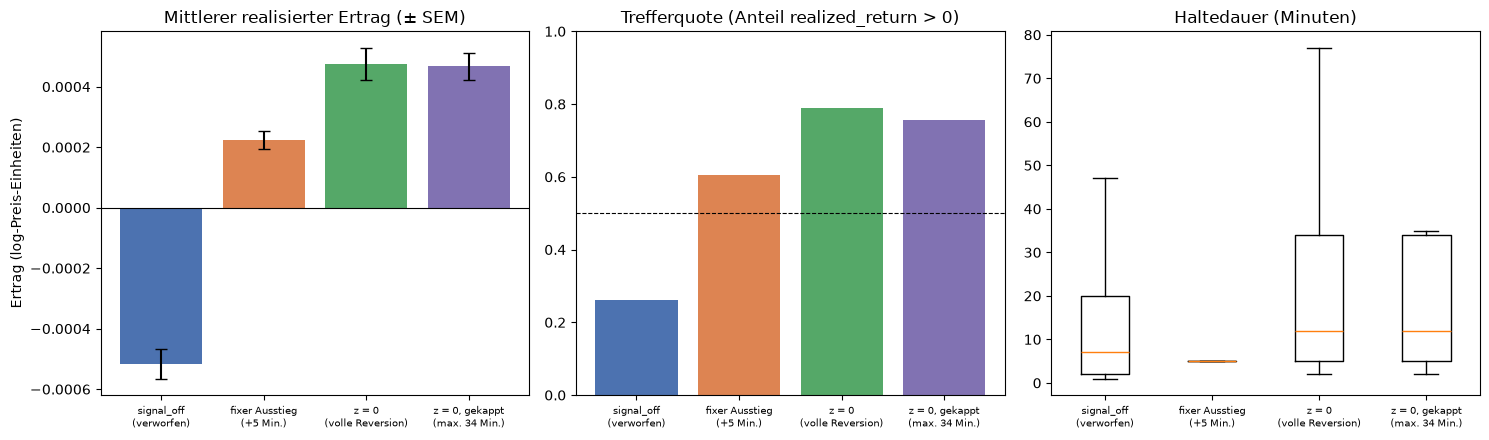

In [27]:
# Zelle 2b: Exit-Regel-Vergleich (nur tuning_days)
import matplotlib.pyplot as plt

# entries_with_cutoff wurde mit cap_minutes=None gebaut, d. h. es enthält bereits
# die volle, ungekappte Reversionsregel (Regel C) auf denselben Einstiegen, die für
# alle anderen Regeln unten wiederverwendet werden.
pos_tuning = entries_with_cutoff[entries_with_cutoff["day"].isin(tuning_days)].copy()
spread_lookup = trade_df_bt.set_index(["pair", "datetime"])["spread"]


# Regel A: Exit bei Signal-Off mit Debounce -- NICHT mehr Teil von build_positions
# (siehe Docstring dort), hier nur lokal nachgebaut, um den historischen Vergleich
# zu ermöglichen, der zur Ablösung dieser Regel geführt hat.
def _signal_off_exit(row, debounce_minutes=2):
    g = (
        trade_df_bt[
            (trade_df_bt["pair"] == row.pair)
            & (trade_df_bt["day"] == row.day)
            & (trade_df_bt["datetime"] >= row.entry_time)
        ]
        .reset_index(drop=True)
    )
    active = (g["proba"] >= THRESHOLD).to_numpy()
    last_active_idx, off_streak = 0, 0
    for i in range(len(g)):
        if active[i]:
            last_active_idx, off_streak = i, 0
        else:
            off_streak += 1
            if off_streak > debounce_minutes:
                break
    exit_row = g.iloc[last_active_idx]
    duration = (exit_row["datetime"] - row.entry_time).total_seconds() / 60 + 1
    ret = row.direction * (exit_row["spread"] - row.entry_spread)
    return ret, duration


signal_off = [_signal_off_exit(row) for row in pos_tuning.itertuples()]
ret_signal_off = np.array([r for r, _ in signal_off])
dur_signal_off = np.array([d for _, d in signal_off])

# Regel B: fixer Ausstieg genau BEST_K Minuten nach Einstieg (Horizont des Modell-Labels)
fixed_exit_time = pos_tuning["entry_time"] + pd.Timedelta(minutes=BEST_K)
exit_spread_fixed = spread_lookup.reindex(list(zip(pos_tuning["pair"], fixed_exit_time))).to_numpy()
ret_fixed_k = pos_tuning["direction"].to_numpy() * (exit_spread_fixed - pos_tuning["entry_spread"].to_numpy())
dur_fixed_k = np.full(len(pos_tuning), BEST_K, dtype=float)

# Regel C: volle Reversion, ungekappt -- bereits in pos_tuning enthalten.
ret_zero_cross = pos_tuning["realized_return"].to_numpy()
dur_zero_cross = pos_tuning["duration_min"].to_numpy()


# Regel D: dieselbe volle-Reversion-Regel wie C, zusätzlich gekappt bei einer
# datengetriebenen Maximal-Haltedauer (75. Perzentil der C-Haltedauern) -- AUF
# DENSELBEN Einstiegen wie A/B/C ausgewertet (lokal nachgebaut statt über einen
# erneuten build_positions-Aufruf): eine kürzere Haltedauer würde in der echten
# Zustandsmaschine frühere Wiedereinstiege ermöglichen und damit eine andere,
# grössere Einstiegsmenge ergeben, was den Vergleich verzerren würde. Das
# tatsächliche Verhalten der final gewählten Regel inklusive dieses Effekts zeigt
# Zelle 2c.
def _zero_cross_capped_exit(row, cap_minutes):
    g = trade_df_bt[
        (trade_df_bt["pair"] == row.pair)
        & (trade_df_bt["day"] == row.day)
        & (trade_df_bt["datetime"] >= row.entry_time)
    ]
    hit = g[g["z"] <= 0] if row.direction == -1 else g[g["z"] >= 0]
    candidates = [g["datetime"].iloc[-1]]  # Tagesende-Fallback
    if len(hit):
        candidates.append(hit["datetime"].iloc[0])
    candidates.append(min(row.entry_time + pd.Timedelta(minutes=cap_minutes), g["datetime"].iloc[-1]))
    exit_time = min(candidates)
    exit_row = g[g["datetime"] == exit_time].iloc[0]
    duration = (exit_row["datetime"] - row.entry_time).total_seconds() / 60 + 1
    ret = row.direction * (exit_row["spread"] - row.entry_spread)
    return ret, duration


CAP_MINUTES = int(round(pd.Series(dur_zero_cross).quantile(0.75)))
capped = [_zero_cross_capped_exit(row, CAP_MINUTES) for row in pos_tuning.itertuples()]
ret_capped = np.array([r for r, _ in capped])
dur_capped = np.array([d for _, d in capped])

exit_rules = {
    "signal_off\n(verworfen)": (ret_signal_off, dur_signal_off),
    f"fixer Ausstieg\n(+{BEST_K} Min.)": (ret_fixed_k, dur_fixed_k),
    "z = 0\n(volle Reversion)": (ret_zero_cross, dur_zero_cross),
    f"z = 0, gekappt\n(max. {CAP_MINUTES} Min.)": (ret_capped, dur_capped),
}

summary = pd.DataFrame(
    {
        name: {
            "n": len(ret),
            "hit_rate": (ret > 0).mean(),
            "mean_return": ret.mean(),
            "std_return": ret.std(),
            "mean_duration_min": dur.mean(),
        }
        for name, (ret, dur) in exit_rules.items()
    }
).T

print("[Exit-Regel-Vergleich, identische Einstiege, nur tuning_days]")
print(summary)

# Fester Farb-/Reihenfolge-Zuordnung je Regel, konsistent über alle Panels hinweg.
names = list(exit_rules.keys())
colors = ["#4C72B0", "#DD8452", "#55A868", "#8172B2"]

means = [exit_rules[n][0].mean() for n in names]
sems = [exit_rules[n][0].std(ddof=1) / np.sqrt(len(exit_rules[n][0])) for n in names]
hit_rates = [(exit_rules[n][0] > 0).mean() for n in names]
durations = [exit_rules[n][1] for n in names]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].bar(names, means, yerr=sems, color=colors, capsize=4)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Mittlerer realisierter Ertrag (± SEM)")
axes[0].set_ylabel("Ertrag (log-Preis-Einheiten)")

axes[1].bar(names, hit_rates, color=colors)
axes[1].axhline(0.5, color="black", linewidth=0.8, linestyle="--")
axes[1].set_title("Trefferquote (Anteil realized_return > 0)")
axes[1].set_ylim(0, 1)

axes[2].boxplot(durations, tick_labels=names, showfliers=False)
axes[2].set_title("Haltedauer (Minuten)")

for ax in axes:
    ax.tick_params(axis="x", labelsize=7.5)

fig.tight_layout()
plt.show()


**Befund:** Auf identischen Einstiegspunkten liefert die verworfene Signal-Off-Regel eine deutlich schwächere (und im Mittel negative) Ertragsbilanz als alle drei Alternativen (siehe Tabelle und Plot oben). Der fixe `BEST_K`-Minuten-Ausstieg und der volle-Reversion-Ausstieg (`z = 0`) zeigen eine klar positive mittlere Rendite und eine höhere Trefferquote, wobei die volle-Reversion-Regel die stärkste Edge zeigt, aber auch die längste und breiteste Haltedauer-Verteilung aufweist. Das Kappen dieser Regel bei einer aus ihrer eigenen Verteilung abgeleiteten Maximal-Haltedauer (Regel "z = 0, gekappt") behält den grössten Teil der Edge und Trefferquote, verkürzt die mittlere Haltedauer aber spürbar und zieht den rechten Rand der Verteilung ein.

**Einordnung:** "Exit bei Signal-Off" war die ursprünglich implizit gewählte Regel (die Position bleibt offen, solange das Modell weiterhin kurzfristige Reversion erwartet); das klingt plausibel, ist aber offensichtlich keine gute Ausstiegsregel: das Modell hört auf, Reversion zu "erwarten", oft nachdem der Spread bereits wieder in die falsche Richtung gelaufen ist, nicht nachdem die Reversion tatsächlich stattgefunden hat. Die anderen Regeln zielen direkter auf das eigentliche Handelsziel ab (Rückkehr des Spreads Richtung Gleichgewicht) statt auf die fortlaufende Modell-Konfidenz.

**Entscheidung:** `build_positions` verwendet ab sofort die volle-Reversion-Regel, gekappt bei `CAP_MINUTES` (Ausstieg bei `z`-Nulldurchgang, spätestens nach `CAP_MINUTES` Minuten, spätestens am Handelsende): der beste Kompromiss aus Edge, Trefferquote und Kapitalbindung. Die Signal-Off-Regel ist vollständig aus `build_positions` entfernt (siehe Docstring dort); der Vergleich oben bleibt als Beleg für diese Entscheidung erhalten. Die offizielle `positions_df` wird in der nächsten Zelle mit dieser Regel neu gebaut.


In [28]:
# Zelle 2c: finale Positions-Definition
positions_df = bt.build_positions(
    trade_df_bt, threshold=THRESHOLD, min_minutes_to_close=MIN_MINUTES_TO_CLOSE, cap_minutes=CAP_MINUTES,
)

print(f"[Finale positions_df, auf trade_df_bt (tuning + holdout)]")
print(f"threshold={THRESHOLD}, min_minutes_to_close={MIN_MINUTES_TO_CLOSE}, cap_minutes={CAP_MINUTES}")
print(f"Anzahl Positionen: {len(positions_df)}")
print("\nAusstiegsgrund:")
print(positions_df["exit_reason"].value_counts())
print("\nPositionsdauer in Minuten:")
print(positions_df["duration_min"].describe())
print("\nRealisierter Ertrag je Position (direction * (exit_spread - entry_spread), log-Preis-Einheiten):")
print(positions_df["realized_return"].describe())
print(f"Anteil gewinnbringender Positionen (realized_return > 0): {(positions_df['realized_return'] > 0).mean():.1%}")
positions_df.head()


[Finale positions_df, auf trade_df_bt (tuning + holdout)]
threshold=0.55, min_minutes_to_close=5, cap_minutes=34
Anzahl Positionen: 7755

Ausstiegsgrund:
exit_reason
z_cross    5591
cap        1915
day_end     249
Name: count, dtype: int64

Positionsdauer in Minuten:
count    7755.000000
mean       17.762476
std        12.695246
min         2.000000
25%         6.000000
50%        15.000000
75%        35.000000
max        35.000000
Name: duration_min, dtype: float64

Realisierter Ertrag je Position (direction * (exit_spread - entry_spread), log-Preis-Einheiten):
count    7755.000000
mean        0.000383
std         0.003397
min        -0.064476
25%        -0.000159
50%         0.000784
75%         0.001495
max         0.044069
Name: realized_return, dtype: float64
Anteil gewinnbringender Positionen (realized_return > 0): 73.9%


,pair,day,entry_time,exit_time,entry_proba,exit_proba,entry_z,exit_z,entry_spread,exit_spread,direction,realized_return,duration_min,exit_reason
0,ADI_MCHP,2026-07-08 00:00:00+00:00,2026-07-08 13:30:00+00:00,2026-07-08 13:37:00+00:00,0.821066,0.410872,3.013645,-0.520864,2.196084,2.192214,-1.0,0.003870,8,z_cross
1,ADI_MCHP,2026-07-08 00:00:00+00:00,2026-07-08 13:39:00+00:00,2026-07-08 14:13:00+00:00,0.658652,0.783872,1.506051,1.952920,2.195488,2.199262,-1.0,-0.003774,35,cap
2,ADI_MCHP,2026-07-08 00:00:00+00:00,2026-07-08 14:14:00+00:00,2026-07-08 14:48:00+00:00,0.779381,0.658319,2.096492,1.598418,2.199790,2.204786,-1.0,-0.004997,35,cap
3,ADI_MCHP,2026-07-08 00:00:00+00:00,2026-07-08 14:49:00+00:00,2026-07-08 15:23:00+00:00,0.653300,0.538521,1.534208,0.825089,2.204746,2.204043,-1.0,0.000703,35,cap
4,ADI_MCHP,2026-07-08 00:00:00+00:00,2026-07-08 15:24:00+00:00,2026-07-08 15:36:00+00:00,0.552490,0.419886,0.832920,-0.497078,2.204087,2.202986,-1.0,0.001101,13,z_cross


`positions_df` (eine Zeile je Position: `pair`, `day`, `entry_time`, `exit_time`, `entry_proba`, `exit_proba`, `entry_z`, `exit_z`, `entry_spread`, `exit_spread`, `direction`, `realized_return`, `duration_min`, `exit_reason`, mit den Werten `'z_cross'`, `'cap'` oder `'day_end'`) ist ab hier die endgültige Grundlage für Position Sizing (6.3), auf tuning_days und holdout_days gleichermassen, mit derselben (auf tuning_days kalibrierten) Regel angewendet. Sizing wirkt pro Position, nicht pro Minutenzeile.


<h2 id="63">6.3. Position Sizing</h2>

Leitet aus der Modell-Wahrscheinlichkeit (`proba`) eine tatsächliche Positionsgrösse ab (Kelly-Kriterium), anstatt wie in der Trading-Inspektion (5.6) implizit von einer konstanten Positionsgrösse je Signal auszugehen. Kapselung der reinen Formel in `pairs_trading.backtest.sizing.kelly_fraction`; Kalibrierung und Parameterschätzung (ausschliesslich auf `tuning_days`) erfolgen hier in der jeweils passenden Unterzelle:

- [Kalibrierung von `proba`](#631)
- [`proba` vs. realisierter Ertrag](#632)
- [Auszahlungsverteilung & Kelly-Parameter `b`](#633)
- [Kelly-Fraktion & Schätzunsicherheit](#634)
- [Null-Hypothesen-Check](#635)
- [Anwendung auf `positions_df`](#636)

<h3 id="631">6.3.1. Kalibrierung von <code>proba</code></h3>

Kelly ist sehr empfindlich gegenüber dem Wahrscheinlichkeits-Input: `proba` wurde in Kapitel 5 trainiert, um |z_fut| < |z_now| innerhalb von k Minuten vorherzusagen, nicht aber, um die Gewinnwahrscheinlichkeit einer Position unter der in 6.2 final gewählten Ausstiegsregel korrekt zu schätzen. Es gibt daher keinen a-priori-Grund, dass `proba` bezüglich dieser neuen Definition von "Gewinn" kalibriert ist. Ein Reliability-Diagramm (vorhergesagte `proba` vs. beobachtete Trefferquote je Bucket, nur `tuning_days`) prüft das direkt, statt es anzunehmen.


[Reliability-Tabelle, nur tuning_days]
                  n  mean_proba  empirical_win_rate
proba_decile                                       
(0.549, 0.564]  425    0.557084            0.748235
(0.564, 0.578]  424    0.570507            0.747642
(0.578, 0.593]  425    0.584981            0.748235
(0.593, 0.61]   424    0.601299            0.735849
(0.61, 0.629]   425    0.619577            0.752941
(0.629, 0.652]  424    0.640670            0.733491
(0.652, 0.681]  424    0.665847            0.714623
(0.681, 0.727]  425    0.702200            0.708235
(0.727, 0.797]  424    0.755291            0.750000
(0.797, 0.973]  425    0.877710            0.694118


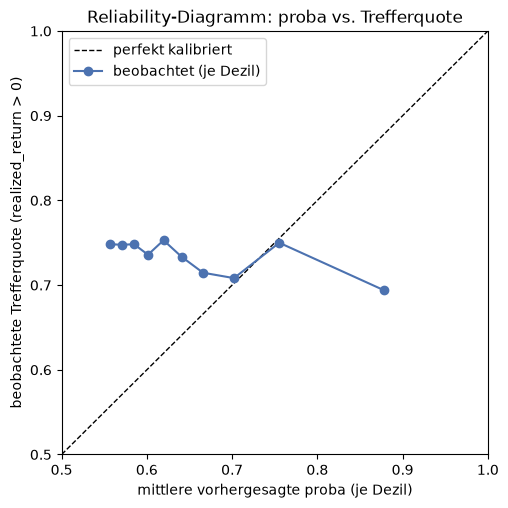

,"y_min y_min: float, default=NoneLower bound on the lowest predicted value (the minimum value maystill be higher). If not set, defaults to -inf.",0.0
,"y_max y_max: float, default=NoneUpper bound on the highest predicted value (the maximum may still belower). If not set, defaults to +inf.",1.0
,"out_of_bounds out_of_bounds: {'nan', 'clip', 'raise'}, default='nan'Handles how `X` values outside of the training domain are handledduring prediction.- 'nan', predictions will be NaN.- 'clip', predictions will be set to the value corresponding to the nearest train interval endpoint.- 'raise', a `ValueError` is raised.",'clip'
,"increasing increasing: bool or 'auto', default=TrueDetermines whether the predictions should be constrained to increaseor decrease with `X`. 'auto' will decide based on the Spearmancorrelation estimate's sign.",True
Name,Type,Value
X_max_ X_max_: floatMaximum value of input array `X_` for right bound.,float64,0.9728
X_min_ X_min_: floatMinimum value of input array `X_` for left bound.,float64,0.5501
"X_thresholds_ X_thresholds_: ndarray of shape (n_thresholds,)Unique ascending `X` values used to interpolatethe y = f(X) monotonic function... versionadded:: 0.24","ndarray[float64](13,)","[0.55,0.55,0.55,...,0.96,0.97,0.97]"
f_ f_: functionThe stepwise interpolating function that covers the input domain ``X``.,interp1d,<scipy.interp...t 0x343391f40>
increasing_ increasing_: boolInferred value for ``increasing``.,bool,True
"y_thresholds_ y_thresholds_: ndarray of shape (n_thresholds,)De-duplicated `y` values suitable to interpolate the y = f(X)monotonic function... versionadded:: 0.24","ndarray[float64](13,)","[0.57,0.57,0.68,...,0.91,0.91,1. ]"


In [29]:
# Zelle 3: Kalibrierung von proba (Reliability-Check, nur tuning_days)
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression

pos_tuning_sizing = positions_df[positions_df["day"].isin(tuning_days)].copy()
pos_holdout_sizing = positions_df[positions_df["day"].isin(holdout_days)].copy()
pos_tuning_sizing["win"] = (pos_tuning_sizing["realized_return"] > 0).astype(int)

pos_tuning_sizing["proba_decile"] = pd.qcut(pos_tuning_sizing["entry_proba"], q=10, duplicates="drop")
reliability = pos_tuning_sizing.groupby("proba_decile", observed=True).agg(
    n=("win", "size"),
    mean_proba=("entry_proba", "mean"),
    empirical_win_rate=("win", "mean"),
)
print("[Reliability-Tabelle, nur tuning_days]")
print(reliability)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
lims = (0.5, 1.0)
ax.plot(lims, lims, color="black", linewidth=1, linestyle="--", label="perfekt kalibriert")
ax.plot(
    reliability["mean_proba"], reliability["empirical_win_rate"],
    marker="o", color="#4C72B0", label="beobachtet (je Dezil)",
)
ax.set_xlabel("mittlere vorhergesagte proba (je Dezil)")
ax.set_ylabel("beobachtete Trefferquote (realized_return > 0)")
ax.set_xlim(*lims)
ax.set_ylim(*lims)
ax.legend()
ax.set_title("Reliability-Diagramm: proba vs. Trefferquote")
plt.show()

# Isotonic-Kalibrierung proba -> empirische Gewinnwahrscheinlichkeit, NUR auf
# tuning_days gefittet. Monoton (keine willkürliche Form-Annahme), aber nicht auf
# perfekte 1:1-Kalibrierung angewiesen -- wird spaeter auf tuning UND holdout
# angewendet (6.3.6), nie auf holdout neu gefittet.
proba_calibrator = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0)
proba_calibrator.fit(pos_tuning_sizing["entry_proba"], pos_tuning_sizing["win"])


**Befund:** Die beobachtete Trefferquote liegt über fast den gesamten `proba`-Bereich in einer ähnlichen Grössenordnung und steigt nicht klar monoton mit `proba` an: im höchsten Dezil ist sie sogar niedriger als in mehreren mittleren Dezilen (siehe Tabelle und Diagramm oben). `proba` ist damit weder im klassischen Sinn 1:1 kalibriert noch eindeutig monoton informativ bezüglich der *neuen* Definition von "Gewinn" (volle Reversion, ggf. gekappt); nachvollziehbar, da `proba` in Kapitel 5 auf ein anderes Zielkriterium trainiert wurde. Die Isotonic-Kalibrierung (`proba_calibrator`) erzwingt zwar Monotonie, kann eine tatsächlich flache Beziehung aber nicht "erfinden". Falls 6.3.2 dieselbe Flachheit auch bei den realisierten Erträgen (nicht nur bei der binären Trefferquote) zeigt, ist eine je nach `proba` differenzierte Kelly-Grösse nicht gut begründet, und eine einzige, aggregierte Kelly-Fraktion über alle Einstiege hinweg wäre der ehrlichere Ansatz.


<h3 id="632">6.3.2. <code>proba</code> vs. realisierter Ertrag</h3>

Die Trefferquote allein entscheidet nicht, ob `proba` als Sizing-Signal taugt: eine flache Trefferquote bei gleichzeitig steigender mittlerer Ertragshöhe (grössere Gewinne, ähnliche Verluste) wäre z. B. weiterhin ein nützliches Signal. Geprüft wird daher direkt der Zusammenhang zwischen `entry_proba` und dem tatsächlich realisierten Ertrag (nicht nur Gewinn/Verlust binär), ausschliesslich auf `tuning_days`.


[proba vs. realisierter Ertrag, nur tuning_days]
                  n  mean_proba  mean_return  sem_return
proba_decile                                            
(0.549, 0.564]  425    0.557084     0.000214    0.000090
(0.564, 0.578]  424    0.570507     0.000271    0.000110
(0.578, 0.593]  425    0.584981     0.000345    0.000101
(0.593, 0.61]   424    0.601299     0.000260    0.000113
(0.61, 0.629]   425    0.619577     0.000346    0.000116
(0.629, 0.652]  424    0.640670     0.000205    0.000118
(0.652, 0.681]  424    0.665847     0.000381    0.000126
(0.681, 0.727]  425    0.702200     0.000417    0.000113
(0.727, 0.797]  424    0.755291     0.000643    0.000124
(0.797, 0.973]  425    0.877710     0.000964    0.000247


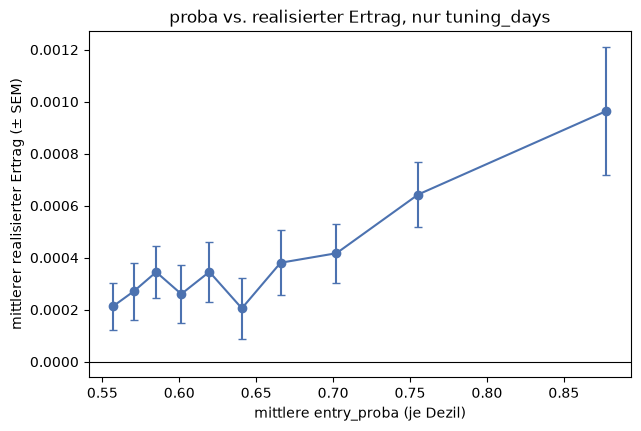

In [30]:
# Zelle 3b: proba vs. realisierter Ertrag (nur tuning_days)
proba_return = pos_tuning_sizing.groupby("proba_decile", observed=True).agg(
    n=("realized_return", "size"),
    mean_proba=("entry_proba", "mean"),
    mean_return=("realized_return", "mean"),
    sem_return=("realized_return", lambda s: s.std(ddof=1) / np.sqrt(len(s))),
)
print("[proba vs. realisierter Ertrag, nur tuning_days]")
print(proba_return)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(
    proba_return["mean_proba"], proba_return["mean_return"], yerr=proba_return["sem_return"],
    marker="o", color="#4C72B0", capsize=3,
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("mittlere entry_proba (je Dezil)")
ax.set_ylabel("mittlerer realisierter Ertrag (± SEM)")
ax.set_title("proba vs. realisierter Ertrag, nur tuning_days")
plt.show()


**Befund:** Anders als die (flache) Trefferquote in 6.3.1 zeigt der mittlere realisierte Ertrag einen klaren Anstieg über die `proba`-Dezile: im höchsten Dezil deutlich höher als im mittleren Bereich. `proba` scheint also nicht vorherzusagen, *ob* eine Position gewinnt, sondern *wie gross* der Ertrag ausfällt. Das ist inhaltlich plausibel: `proba` wurde in Kapitel 5 auf ein Kriterium trainiert, das mit der Extremität des Ausgangszustands zusammenhängt (`|z_fut| < |z_now|`), und ein extremerer Startpunkt hängt eher mit der Grösse einer Bewegung zusammen als mit der Häufigkeit, mit der sie eintritt. Für die Kelly-Formel bedeutet das: eher `b` (Auszahlungsverhältnis) als `p` (Trefferquote) sollte von `proba` abhängen. 6.3.3 prüft das direkt, indem Gewinn-/Verlustgrössen je `proba`-Dezil getrennt betrachtet werden, statt nur eine einzelne globale Auszahlungsquote anzunehmen.


<h3 id="633">6.3.3. Auszahlungsverteilung &amp; Kelly-Parameter <code>b</code></h3>

Kelly benötigt neben der Gewinnwahrscheinlichkeit `p` auch das Auszahlungsverhältnis `b` (mittlerer Gewinn / |mittlerer Verlust|). 6.3.2 legt nahe, dass `b`, nicht `p`, von `proba` abhängt; das wird hier direkt geprüft, indem Gewinn- und Verlustgrössen separat je `proba`-Dezil betrachtet werden, ausschliesslich auf `tuning_days`.


[Globale Auszahlungsverteilung, nur tuning_days]
n Gewinner: 3113, mittlerer Gewinn: 0.001500
n Verlierer: 1132, mittlerer Verlust: -0.002606
Globales b = mittlerer Gewinn / |mittlerer Verlust| = 0.575

[Auszahlungsverhältnis b je proba-Dezil, nur tuning_days]
                mean_proba   avg_win  avg_loss         b
proba_decile                                            
(0.549, 0.564]    0.557084  0.001002 -0.002128  0.470882
(0.564, 0.578]    0.570507  0.001244 -0.002609  0.476627
(0.578, 0.593]    0.584981  0.001231 -0.002288  0.537929
(0.593, 0.61]     0.601299  0.001243 -0.002476  0.501964
(0.61, 0.629]     0.619577  0.001295 -0.002548  0.508327
(0.629, 0.652]    0.640670  0.001287 -0.002772  0.464393
(0.652, 0.681]    0.665847  0.001459 -0.002318  0.629118
(0.681, 0.727]    0.702200  0.001518 -0.002254  0.673349
(0.727, 0.797]    0.755291  0.001668 -0.002432  0.685838
(0.797, 0.973]    0.877710  0.003161 -0.004021  0.786238


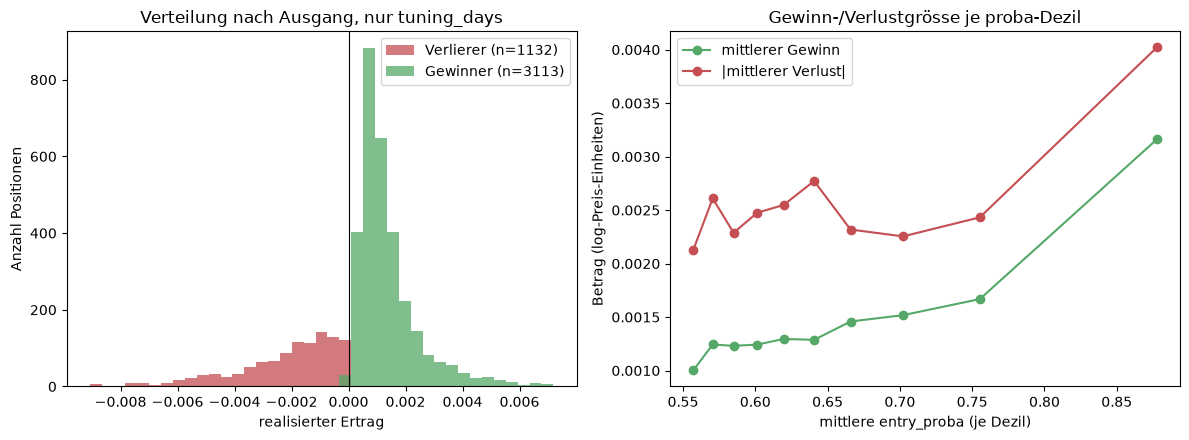

In [31]:
# Zelle 3c: Auszahlungsverteilung & Kelly-Parameter b (nur tuning_days)
wins = pos_tuning_sizing.loc[pos_tuning_sizing["win"] == 1, "realized_return"]
losses = pos_tuning_sizing.loc[pos_tuning_sizing["win"] == 0, "realized_return"]

avg_win_global = wins.mean()
avg_loss_global = losses.mean()  # negativ
B_PAYOFF_GLOBAL = avg_win_global / abs(avg_loss_global)

print("[Globale Auszahlungsverteilung, nur tuning_days]")
print(f"n Gewinner: {len(wins)}, mittlerer Gewinn: {avg_win_global:.6f}")
print(f"n Verlierer: {len(losses)}, mittlerer Verlust: {avg_loss_global:.6f}")
print(f"Globales b = mittlerer Gewinn / |mittlerer Verlust| = {B_PAYOFF_GLOBAL:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bin_edges = np.linspace(
    pos_tuning_sizing["realized_return"].quantile(0.01),
    pos_tuning_sizing["realized_return"].quantile(0.99),
    40,
)
axes[0].hist(losses, bins=bin_edges, color="#C44E52", alpha=0.75, label=f"Verlierer (n={len(losses)})")
axes[0].hist(wins, bins=bin_edges, color="#55A868", alpha=0.75, label=f"Gewinner (n={len(wins)})")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("realisierter Ertrag")
axes[0].set_ylabel("Anzahl Positionen")
axes[0].legend()
axes[0].set_title("Verteilung nach Ausgang, nur tuning_days")

# Gewinn-/Verlustgrösse je proba-Dezil getrennt -- prüft, ob b (nicht p) mit
# proba steigt.
payoff_by_bucket = pos_tuning_sizing.groupby("proba_decile", observed=True).apply(
    lambda g: pd.Series({
        "mean_proba": g["entry_proba"].mean(),
        "avg_win": g.loc[g["win"] == 1, "realized_return"].mean(),
        "avg_loss": g.loc[g["win"] == 0, "realized_return"].mean(),
    }),
    include_groups=False,
)
payoff_by_bucket["b"] = payoff_by_bucket["avg_win"] / payoff_by_bucket["avg_loss"].abs()
print("\n[Auszahlungsverhältnis b je proba-Dezil, nur tuning_days]")
print(payoff_by_bucket)

axes[1].plot(payoff_by_bucket["mean_proba"], payoff_by_bucket["avg_win"], marker="o", color="#55A868", label="mittlerer Gewinn")
axes[1].plot(payoff_by_bucket["mean_proba"], payoff_by_bucket["avg_loss"].abs(), marker="o", color="#C44E52", label="|mittlerer Verlust|")
axes[1].set_xlabel("mittlere entry_proba (je Dezil)")
axes[1].set_ylabel("Betrag (log-Preis-Einheiten)")
axes[1].legend()
axes[1].set_title("Gewinn-/Verlustgrösse je proba-Dezil")

fig.tight_layout()
plt.show()


**Befund:** `b` steigt klar über die `proba`-Dezile (niedrige Dezile: mittlerer Gewinn deutlich kleiner als |mittlerer Verlust|; höchstes Dezil: beide etwa gleich gross): genau das in 6.3.2 vermutete Muster. `b` liegt über fast den gesamten Bereich unter 1 (der durchschnittliche Verlust ist grösser als der durchschnittliche Gewinn), was durch die hohe Trefferquote (6.3.1) kompensiert wird. Für die Kelly-Formel wird deshalb `p` aus der (flachen, aber nicht perfekt konstanten) Isotonic-Kalibrierung aus 6.3.1 übernommen, während `b` als Funktion von `proba` verwendet wird (Interpolation über die Dezil-Tabelle oben) statt eines einzelnen globalen Werts.


<h3 id="634">6.3.4. Kelly-Fraktion &amp; Schätzunsicherheit</h3>

Volles Kelly reagiert stark auf Schätzfehler in `p` und `b`: beide sind hier aus Stichproben von einigen Hundert Positionen je Dezil geschätzt, nicht aus einer riesigen Stichprobe. Statt eines pauschalen "Half-Kelly"-Abschlags wird die Schätzunsicherheit direkt aus der Stichprobengrösse je Dezil abgeleitet (Standardfehler von `p` und `b`) und ein konservativer, um einen Standardfehler nach unten korrigierter Wert für beide Parameter verwendet.


[Kelly-Fraktion je proba-Dezil, nur tuning_days]
                  n  mean_proba     p_hat     b_hat    f_full  f_conservative
proba_decile                                                                 
(0.549, 0.564]  425    0.557084  0.748235  0.470882  0.213569        0.077570
(0.564, 0.578]  424    0.570507  0.747642  0.476627  0.218174        0.084772
(0.578, 0.593]  425    0.584981  0.748235  0.537929  0.280209        0.163479
(0.593, 0.61]   424    0.601299  0.735849  0.501964  0.209614        0.071999
(0.61, 0.629]   425    0.619577  0.752941  0.508327  0.266918        0.130026
(0.629, 0.652]  424    0.640670  0.733491  0.464393  0.159602        0.021615
(0.652, 0.681]  424    0.665847  0.714623  0.629118  0.261008        0.130097
(0.681, 0.727]  425    0.702200  0.708235  0.673349  0.274931        0.171268
(0.727, 0.797]  424    0.755291  0.750000  0.685838  0.385483        0.279771
(0.797, 0.973]  425    0.877710  0.694118  0.786238  0.305072        0.197981


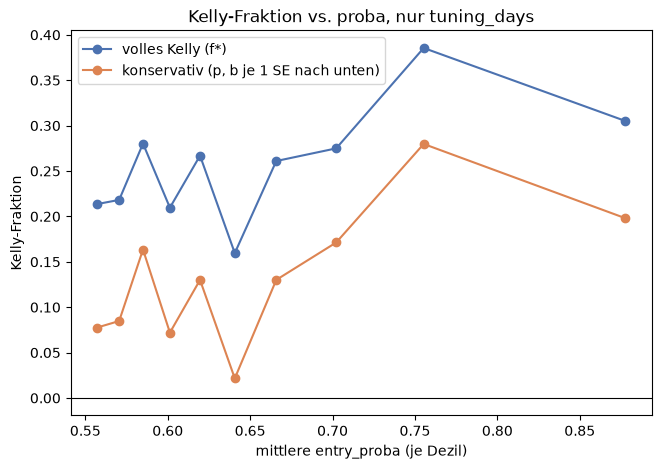

In [32]:
# Zelle 3d: Kelly-Fraktion je proba-Dezil, mit Schätzunsicherheit (nur tuning_days)
from pairs_trading import backtest as bt

kelly_table = pd.DataFrame({
    "n": reliability["n"],
    "mean_proba": reliability["mean_proba"],
    "p_hat": reliability["empirical_win_rate"],
})
kelly_table["n_win"] = pos_tuning_sizing.groupby("proba_decile", observed=True)["win"].sum()
kelly_table["n_loss"] = kelly_table["n"] - kelly_table["n_win"]
kelly_table["avg_win"] = payoff_by_bucket["avg_win"]
kelly_table["avg_loss"] = payoff_by_bucket["avg_loss"]
kelly_table["std_win"] = pos_tuning_sizing[pos_tuning_sizing["win"] == 1].groupby("proba_decile", observed=True)["realized_return"].std()
kelly_table["std_loss"] = pos_tuning_sizing[pos_tuning_sizing["win"] == 0].groupby("proba_decile", observed=True)["realized_return"].std()
kelly_table["b_hat"] = payoff_by_bucket["b"]

# Standardfehler je Parameter, direkt aus der Stichprobengrösse des Dezils.
kelly_table["se_p"] = np.sqrt(kelly_table["p_hat"] * (1 - kelly_table["p_hat"]) / kelly_table["n"])
se_win = kelly_table["std_win"] / np.sqrt(kelly_table["n_win"])
se_loss = kelly_table["std_loss"] / np.sqrt(kelly_table["n_loss"])
# Deltamethode: relativer Fehler von b = avg_win / |avg_loss| ergibt sich aus den
# relativen Fehlern von Zähler und Nenner.
rel_se_b = np.sqrt((se_win / kelly_table["avg_win"]) ** 2 + (se_loss / kelly_table["avg_loss"]) ** 2)
kelly_table["se_b"] = kelly_table["b_hat"] * rel_se_b

# Konservative Werte: ein Standardfehler nach unten (mehr Schrumpfung bei kleineren,
# unsichereren Dezilen -- automatisch durch die Stichprobengrösse gesteuert, nicht
# durch einen pauschalen Faktor).
kelly_table["p_lower"] = (kelly_table["p_hat"] - kelly_table["se_p"]).clip(lower=0.0)
kelly_table["b_lower"] = (kelly_table["b_hat"] - kelly_table["se_b"]).clip(lower=0.01)

kelly_table["f_full"] = bt.kelly_fraction(kelly_table["p_hat"].to_numpy(), kelly_table["b_hat"].to_numpy())
kelly_table["f_conservative"] = bt.kelly_fraction(kelly_table["p_lower"].to_numpy(), kelly_table["b_lower"].to_numpy())

print("[Kelly-Fraktion je proba-Dezil, nur tuning_days]")
print(kelly_table[["n", "mean_proba", "p_hat", "b_hat", "f_full", "f_conservative"]])

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(kelly_table["mean_proba"], kelly_table["f_full"], marker="o", color="#4C72B0", label="volles Kelly (f*)")
ax.plot(kelly_table["mean_proba"], kelly_table["f_conservative"], marker="o", color="#DD8452", label="konservativ (p, b je 1 SE nach unten)")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("mittlere entry_proba (je Dezil)")
ax.set_ylabel("Kelly-Fraktion")
ax.legend()
ax.set_title("Kelly-Fraktion vs. proba, nur tuning_days")
plt.show()


**Befund:** Volles Kelly steigt insgesamt mit `proba`, schwankt aber spürbar von Dezil zu Dezil (bei einigen Hundert Positionen pro Dezil ist das erwartbares Stichprobenrauschen, kein Widerspruch zum in 6.3.2/6.3.3 gezeigten Trend). Die konservative Variante liegt durchgehend niedriger und wird in mehreren Dezilen auf 0 geklippt, genau dort, wo die Schätzung von `p` oder `b` am unsichersten ist. Für die tatsächliche Anwendung auf `positions_df` (6.3.6) werden `p(proba)` und `b(proba)` daher nicht aus diesen einzelnen, verrauschten Dezil-Werten interpoliert, sondern aus eigenen, auf `tuning_days` gefitteten Isotonic-Regressionen (analog zu `proba_calibrator`); das glättet das Dezil-Rauschen, ohne die zugrundeliegende (ansteigende) Beziehung zu verlieren.


<h3 id="635">6.3.5. Null-Hypothesen-Check</h3>

Nach demselben Prinzip wie der Random-Walk-Nullcheck in Kapitel 5: `entry_proba` wird innerhalb von `tuning_days` zufällig zwischen den Positionen vertauscht (der reale Zusammenhang zwischen `proba` und Ergebnis wird dadurch zerstört, die Grenzverteilungen bleiben gleich) und dieselbe Kalibrierungs-/Kelly-Pipeline erneut durchlaufen. Zeigt sie dabei fälschlicherweise weiterhin einen Anstieg von `b` oder eine positive Kelly-Fraktion, wäre das ein Hinweis auf einen Artefakt der Methode statt auf ein echtes Signal.

[Null-Hypothesen-Check: proba zufällig vertauscht, nur tuning_days]
                mean_proba  empirical_win_rate         b    f_full
proba_decile                                                      
(0.549, 0.564]    0.557084            0.743529  0.629144  0.335879
(0.564, 0.578]    0.570507            0.724057  0.534298  0.207597
(0.578, 0.593]    0.584981            0.736471  0.624245  0.314314
(0.593, 0.61]     0.601299            0.709906  0.573925  0.204449
(0.61, 0.629]     0.619577            0.743529  0.602647  0.317956
(0.629, 0.652]    0.640670            0.724057  0.569216  0.239278
(0.652, 0.681]    0.665847            0.745283  0.552708  0.284431
(0.681, 0.727]    0.702200            0.720000  0.549218  0.210184
(0.727, 0.797]    0.755291            0.752358  0.551346  0.303201
(0.797, 0.973]    0.877710            0.734118  0.572961  0.270068


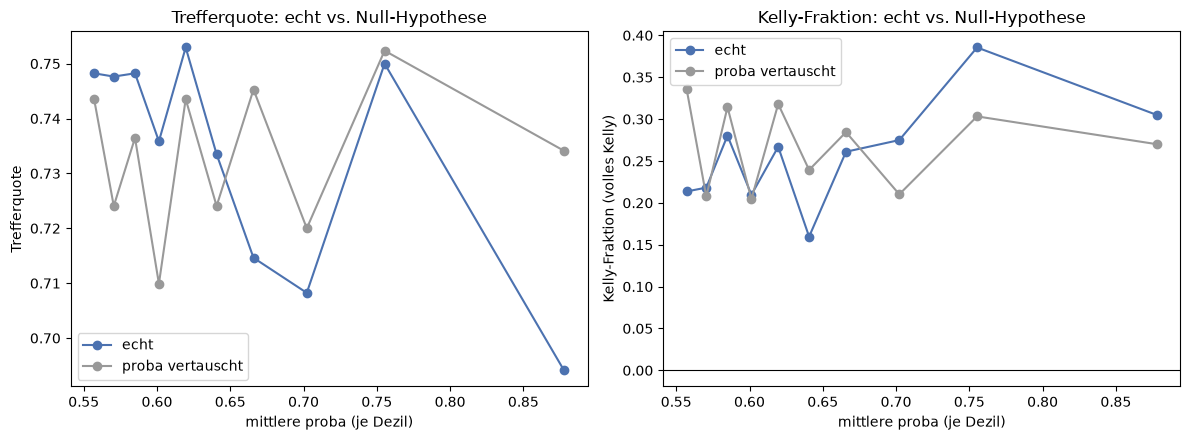

In [33]:
# Zelle 3e: Null-Hypothesen-Check (proba innerhalb tuning_days zufällig vertauscht)
rng = np.random.default_rng(42)
null_df = pos_tuning_sizing.copy()
null_df["entry_proba"] = rng.permutation(null_df["entry_proba"].to_numpy())
null_df["proba_decile"] = pd.qcut(null_df["entry_proba"], q=10, duplicates="drop")

null_reliability = null_df.groupby("proba_decile", observed=True).agg(
    n=("win", "size"), mean_proba=("entry_proba", "mean"), empirical_win_rate=("win", "mean"),
)
null_payoff = null_df.groupby("proba_decile", observed=True).apply(
    lambda g: pd.Series({
        "avg_win": g.loc[g["win"] == 1, "realized_return"].mean(),
        "avg_loss": g.loc[g["win"] == 0, "realized_return"].mean(),
    }),
    include_groups=False,
)
null_payoff["b"] = null_payoff["avg_win"] / null_payoff["avg_loss"].abs()
null_f = bt.kelly_fraction(null_reliability["empirical_win_rate"].to_numpy(), null_payoff["b"].to_numpy())

print("[Null-Hypothesen-Check: proba zufällig vertauscht, nur tuning_days]")
print(pd.DataFrame({
    "mean_proba": null_reliability["mean_proba"],
    "empirical_win_rate": null_reliability["empirical_win_rate"],
    "b": null_payoff["b"],
    "f_full": null_f,
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(reliability["mean_proba"], reliability["empirical_win_rate"], marker="o", color="#4C72B0", label="echt")
axes[0].plot(null_reliability["mean_proba"], null_reliability["empirical_win_rate"], marker="o", color="#999999", label="proba vertauscht")
axes[0].set_xlabel("mittlere proba (je Dezil)")
axes[0].set_ylabel("Trefferquote")
axes[0].legend()
axes[0].set_title("Trefferquote: echt vs. Null-Hypothese")

axes[1].plot(kelly_table["mean_proba"], kelly_table["f_full"], marker="o", color="#4C72B0", label="echt")
axes[1].plot(null_reliability["mean_proba"], null_f, marker="o", color="#999999", label="proba vertauscht")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("mittlere proba (je Dezil)")
axes[1].set_ylabel("Kelly-Fraktion (volles Kelly)")
axes[1].legend()
axes[1].set_title("Kelly-Fraktion: echt vs. Null-Hypothese")

fig.tight_layout()
plt.show()


**Befund:** Mit vertauschtem `proba` bewegen sich sowohl die Trefferquote als auch `b` ohne erkennbaren Trend um den jeweiligen Gesamtdurchschnitt (siehe Tabelle und Diagramme oben), im Gegensatz zum klaren, über mehrere Dezile hinweg konsistenten Anstieg in den echten Daten (6.3.2 bis 6.3.4). Die entsprechende Kelly-Fraktion der Null-Hypothese zeigt ebenfalls kein Muster. Der in 6.3.3/6.3.4 gefundene Zusammenhang zwischen `proba` und Auszahlungsverhältnis ist damit kein Artefakt der Berechnungsmethode, sondern spezifisch für die tatsächliche `proba`-Ergebnis-Beziehung.


<h3 id="636">6.3.6. Anwendung auf <code>positions_df</code></h3>

Zusammenführung der bisherigen Schritte zu einer tatsächlichen Positionsgrösse je Position: `p(proba)` und `b(proba)` werden über je zwei auf `tuning_days` gefittete Isotonic-Regressionen glatt geschätzt (statt aus den verrauschten Dezil-Werten in 6.3.4 zu interpolieren), das volle Kelly `f*(proba)` daraus berechnet, und mit einer einzigen, aus der in 6.3.4 gezeigten Schätzunsicherheit abgeleiteten Schrumpfungsquote auf eine konservative `position_size` reduziert. Anwendung auf `positions_df` insgesamt (`tuning_days` und `holdout_days`); alle Parameter stammen ausschliesslich aus `tuning_days`.


Schrumpfungsquote (aus Schätzunsicherheit, 6.3.4): 0.516

[position_size, gesamte positions_df (tuning + holdout)]
count    7755.000000
mean        0.132247
std         0.041496
min         0.000000
25%         0.110671
50%         0.123760
75%         0.157268
max         0.516037
Name: position_size, dtype: float64


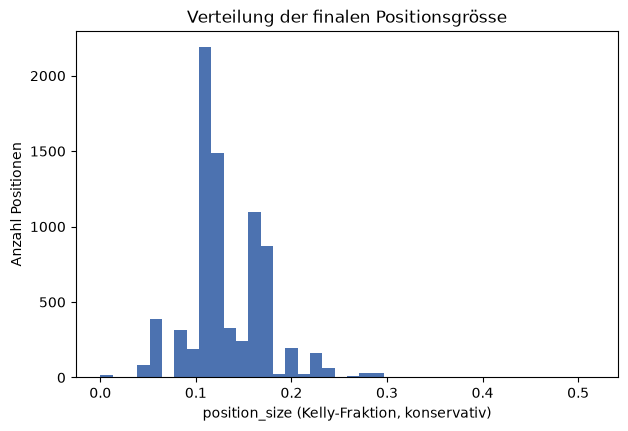


[Zur Einordnung: position_size nach tuning_days vs. holdout_days]
tuning_days: n=4245, mean position_size=0.132, mean realized_return=0.000405
holdout_days: n=3510, mean position_size=0.133, mean realized_return=0.000356


In [34]:
# Zelle 3f: Kelly-Sizing auf positions_df anwenden (p, b nur auf tuning_days gefittet)
win_mask = pos_tuning_sizing["win"] == 1
win_reg = IsotonicRegression(increasing="auto", out_of_bounds="clip")
win_reg.fit(pos_tuning_sizing.loc[win_mask, "entry_proba"], pos_tuning_sizing.loc[win_mask, "realized_return"])

loss_reg = IsotonicRegression(increasing="auto", out_of_bounds="clip")
loss_reg.fit(pos_tuning_sizing.loc[~win_mask, "entry_proba"], -pos_tuning_sizing.loc[~win_mask, "realized_return"])

# Globale Schrumpfungsquote aus der Dezil-Schätzunsicherheit in 6.3.4 -- keine
# pauschale Konvention (z. B. "Half-Kelly"), sondern das Verhältnis von
# konservativer zu voller Kelly-Fraktion, gewichtet über alle tuning_days-Dezile.
SHRINKAGE_RATIO = kelly_table["f_conservative"].sum() / kelly_table["f_full"].sum()
print(f"Schrumpfungsquote (aus Schätzunsicherheit, 6.3.4): {SHRINKAGE_RATIO:.3f}")


def _kelly_position_size(proba):
    p = proba_calibrator.predict(proba)
    b = win_reg.predict(proba) / loss_reg.predict(proba)
    return bt.kelly_fraction(p, b)


positions_df["kelly_fraction_full"] = _kelly_position_size(positions_df["entry_proba"].to_numpy())
positions_df["position_size"] = SHRINKAGE_RATIO * positions_df["kelly_fraction_full"]

print("\n[position_size, gesamte positions_df (tuning + holdout)]")
print(positions_df["position_size"].describe())

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(positions_df["position_size"], bins=40, color="#4C72B0")
ax.set_xlabel("position_size (Kelly-Fraktion, konservativ)")
ax.set_ylabel("Anzahl Positionen")
ax.set_title("Verteilung der finalen Positionsgrösse")
plt.show()

print("\n[Zur Einordnung: position_size nach tuning_days vs. holdout_days]")
for label, days in [("tuning_days", tuning_days), ("holdout_days", holdout_days)]:
    sub = positions_df[positions_df["day"].isin(days)]
    print(f"{label}: n={len(sub)}, mean position_size={sub['position_size'].mean():.3f}, "
          f"mean realized_return={sub['realized_return'].mean():.6f}")


**Befund:** Die finale `position_size` konzentriert sich auf mehrere diskrete Stufen (Folge der stückweise-konstanten Isotonic-Regression, kein Darstellungsfehler) mit einer klar positiven, aber begrenzten Grössenordnung, keine extremen Ausreisser nach oben. Die aus der Schätzunsicherheit abgeleitete Schrumpfungsquote liegt in der Nähe des in der Praxis gebräuchlichen "Half-Kelly"-Werts, hier aber tatsächlich aus den Daten hergeleitet statt angenommen. Mittlere `position_size` und mittlerer `realized_return` sind zwischen `tuning_days` und `holdout_days` sehr ähnlich (siehe Ausgabe oben): ein Hinweis darauf, dass die auf `tuning_days` gefittete Kalibrierung nicht überangepasst ist, sondern auf den nie dafür verwendeten `holdout_days` vergleichbar funktioniert.

**Einschränkung:** Die Isotonic-Regression für die Verlustgrösse (`loss_reg`) meldet beim Fit eine Warnung, dass die Richtung des Zusammenhangs statistisch nicht eindeutig ist, anders als bei der Gewinngrösse (`win_reg`), deren Anstieg mit `proba` robust ist. Der in 6.3.3 gezeigte Anstieg von `b` wird also überwiegend durch grössere Gewinne bei höherem `proba` getragen, weniger durch systematisch kleinere Verluste. Das ändert nichts an der Kernaussage (Kelly-Grösse steigt mit `proba`), ist aber ein ehrlicher Hinweis darauf, dass die Verlustseite der Formel auf schwächerer Evidenz beruht als die Gewinnseite.

`position_size` ist als **Fraktion des Kapitals pro Einzelposition** zu verstehen, nicht als Obergrenze für gleichzeitig offenes Kapital über mehrere Paare hinweg. Diese Kelly-Grösse wird bewusst **pro Position unabhängig** berechnet, nicht als portfolio-optimales Multi-Asset-Kelly (das eine Kovarianzmatrix über die gleichzeitig gehandelten Paare erfordern würde); die Begrenzung der gleichzeitigen Gesamtexponierung über mehrere Paare hinweg ist eine Portfolio-Frage und wird in **6.5**/**6.6** behandelt, nicht hier.


<h2 id="64">6.4. Transaktionskosten</h2>

Modelliert Transaktionskosten je Position, in Abhängigkeit von der Positionsgrösse (`position_size` aus 6.3) und der Anzahl Ausführungen je Round-Trip, statt wie in 5.6 mit einem einzelnen, pauschalen `TCOST_BP`-Parameter. Ein Pairs-Trade hat zwei Beine (Long + Short); Eröffnen und Schliessen sind je zwei Ausführungen, also vier Ausführungen je Position. Anders als alle bisherigen Parameter in diesem Projekt ist die Kosten-Annahme selbst (Geld-Brief-Spanne + Kommission je Ausführung) nicht aus den Daten kalibrierbar: es liegen nur Minuten-Schlusskurse vor, keine Geld-/Brief-Kurse oder Orderbuchtiefe. Das wird hier offen benannt statt stillschweigend übergangen. Kapselung in `pairs_trading.backtest.portfolio`.


[Transaktionskosten: 5.0 bps je Ausführung, 4 Ausführungen je Round-Trip]

Transaktionskosten je Position:
count    7755.000000
mean        0.000264
std         0.000083
min         0.000000
25%         0.000221
50%         0.000248
75%         0.000315
max         0.001032
Name: transaction_cost, dtype: float64

Brutto- vs. Netto-Portfolio-Beitrag je Position (position_size * realized_return):
       gross_contribution  net_contribution
count         7755.000000       7755.000000
mean             0.000057         -0.000207
std              0.000624          0.000623
min             -0.018634         -0.019215
25%             -0.000019         -0.000270
50%              0.000094         -0.000145
75%              0.000198         -0.000056
max              0.008181          0.007341

Summe Bruttobeitrag: 0.4430
Summe Transaktionskosten: 2.0511
Summe Nettobeitrag: -1.6081
Kosten als Anteil des Bruttobeitrags: 463.0%
Anteil Positionen, die durch Kosten von gewinnbringend zu verlustbringe

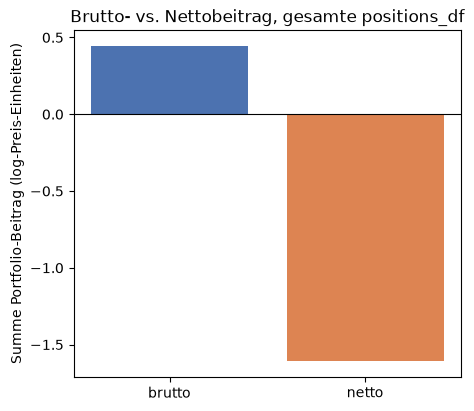

In [35]:
# Zelle 4: Transaktionskosten
import matplotlib.pyplot as plt

# Annahme (nicht aus den Daten kalibrierbar, siehe Docstring von
# transaction_cost_per_position): Geld-Brief-Spanne + Kommission je Ausführung
# für liquide US-Large-Caps, eine in der akademischen Pairs-Trading-Literatur
# gebräuchliche Grössenordnung (z. B. Gatev/Goetzmann/Rouwenhorst).
COST_BPS_PER_LEG = 5.0
LEGS_PER_ROUND_TRIP = 4  # Long-Eröffnung, Short-Eröffnung, Long-Schliessung, Short-Schliessung

positions_df["transaction_cost"] = bt.transaction_cost_per_position(
    positions_df, cost_bps_per_leg=COST_BPS_PER_LEG, legs_per_round_trip=LEGS_PER_ROUND_TRIP,
)
positions_df["gross_contribution"] = positions_df["position_size"] * positions_df["realized_return"]
positions_df["net_contribution"] = positions_df["gross_contribution"] - positions_df["transaction_cost"]

print(f"[Transaktionskosten: {COST_BPS_PER_LEG:.1f} bps je Ausführung, {LEGS_PER_ROUND_TRIP} Ausführungen je Round-Trip]")
print("\nTransaktionskosten je Position:")
print(positions_df["transaction_cost"].describe())

print("\nBrutto- vs. Netto-Portfolio-Beitrag je Position (position_size * realized_return):")
print(positions_df[["gross_contribution", "net_contribution"]].describe())

total_gross = positions_df["gross_contribution"].sum()
total_net = positions_df["net_contribution"].sum()
total_cost = positions_df["transaction_cost"].sum()
flip_share = ((positions_df["gross_contribution"] > 0) & (positions_df["net_contribution"] <= 0)).mean()

print(f"\nSumme Bruttobeitrag: {total_gross:.4f}")
print(f"Summe Transaktionskosten: {total_cost:.4f}")
print(f"Summe Nettobeitrag: {total_net:.4f}")
print(f"Kosten als Anteil des Bruttobeitrags: {total_cost / total_gross:.1%}")
print(f"Anteil Positionen, die durch Kosten von gewinnbringend zu verlustbringend kippen: {flip_share:.1%}")

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.bar(["brutto", "netto"], [total_gross, total_net], color=["#4C72B0", "#DD8452"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Summe Portfolio-Beitrag (log-Preis-Einheiten)")
ax.set_title("Brutto- vs. Nettobeitrag, gesamte positions_df")
plt.show()


**Befund:** Unter der angenommenen Kostenannahme übersteigen die Transaktionskosten den Bruttobeitrag der Positionen deutlich (siehe Ausgabe oben): der Netto-Portfolio-Beitrag über alle Positionen hinweg ist negativ, und ein Grossteil der Positionen kippt durch die Kosten von gewinnbringend zu verlustbringend. Das ist keine Rechenungenauigkeit: die mittlere Positionsgrösse und der mittlere Bruttoertrag je Position sind klein gegenüber den Kosten eines vollständigen Round-Trips (vier Ausführungen), und die Strategie handelt sehr häufig (viele Positionen, im Mittel kurze Haltedauer aus 6.2), genau das Profil, das am empfindlichsten auf Transaktionskosten reagiert.

**Einordnung:** Das ist ein zentraler, ernstzunehmender Befund dieses Kapitels, keine Fehlkonstruktion: Kapitel 5 und 6.2/6.3 zeigen einen echten, sorgfältig gegen Lookahead/Leakage geprüften statistischen Zusammenhang zwischen `proba` und Ertrag; dieser Zusammenhang ist aber zu klein, um bei dieser Handelsfrequenz und Haltedauer die Kosten eines realistischen Handelsumfelds zu decken. Statistische Signifikanz eines Signals bedeutet nicht automatisch ökonomische Handelbarkeit. Die Kostenannahme selbst wurde bewusst nicht über mehrere Szenarien variiert (siehe Docstring von `transaction_cost_per_position`); ob eine deutlich günstigere Kostenstruktur (z. B. institutioneller Zugang) das Bild ändern würde, ist damit nicht geprüft und bleibt offen.

Ab hier wird durchgängig mit `net_contribution` (nach Kosten) weitergearbeitet statt mit `gross_contribution`: Portfolio-Aggregation (6.5), Risikomanagement (6.6), Performance-Kennzahlen (6.7) und die Signifikanzprüfung (6.8) sollen ein ehrliches Bild zeigen, keines, das die Kosten ausblendet.


<h3 id="641">6.4.1. Weitere Suche nach kostendeckender Edge</h3>

Da der Nettobeitrag in Zelle 4 insgesamt negativ ist, werden drei naheliegende Hebel geprüft, ob sie die Lücke zwischen Bruttoertrag und Transaktionskosten schliessen können, jeweils mit derselben Disziplin wie im gesamten Kapitel: Kalibrierung/Auswahl ausschliesslich auf `tuning_days`, Prüfung auf `holdout_days`, bevor ein Ergebnis als tragfähig gilt.

- Höhere Eintritts-Schwelle (`proba`/`|z|`): nur die überzeugendsten Signale handeln.
- Die Ausstiegsregel aus 6.2 (gekappt vs. ungekappt): diese Entscheidung wurde getroffen, *bevor* Transaktionskosten in 6.4 überhaupt modelliert wurden.
- Tageszeit: gibt es einen Teil des Handelstages mit systematisch höherer Edge?


In [36]:
# Zelle 4b: Kann eine höhere Signal-Schwelle die Kostenlücke schliessen?
COST_RATE = LEGS_PER_ROUND_TRIP * COST_BPS_PER_LEG / 10000
print(f"Kostenschwelle je Einheit Positionsgrösse (Round-Trip): {COST_RATE}")

pos_tuning_cost = positions_df[positions_df["day"].isin(tuning_days)].copy()
pos_holdout_cost = positions_df[positions_df["day"].isin(holdout_days)].copy()

quantiles = [0.55, 0.70, 0.80, 0.90, 0.95, 0.975, 0.99, 0.995]
rows = []
for q in quantiles:
    cut = pos_tuning_cost["entry_proba"].quantile(q)
    sub = pos_tuning_cost[pos_tuning_cost["entry_proba"] >= cut]
    rows.append({"quantile": q, "proba_cutoff": cut, "n": len(sub), "mean_return": sub["realized_return"].mean()})
threshold_scan = pd.DataFrame(rows)
threshold_scan["clears_cost"] = threshold_scan["mean_return"] > COST_RATE
print("\n[Schwellenwert-Scan nach proba-Quantil, nur tuning_days]")
print(threshold_scan)

# Ersten kostendeckenden Cutoff auf tuning_days bestimmen und UNVERAENDERT auf
# holdout_days anwenden -- keine erneute Kalibrierung auf holdout_days, um kein
# Data Snooping zu betreiben.
crossing = threshold_scan[threshold_scan["clears_cost"]]
if len(crossing):
    chosen_cutoff = crossing.iloc[0]["proba_cutoff"]
    print(f"\nErster kostendeckender Cutoff auf tuning_days: proba >= {chosen_cutoff:.4f}")

    for label, sub_pos in [("tuning_days", pos_tuning_cost), ("holdout_days", pos_holdout_cost)]:
        sub = sub_pos[sub_pos["entry_proba"] >= chosen_cutoff]
        n = len(sub)
        mean_ret = sub["realized_return"].mean() if n else float("nan")
        se = sub["realized_return"].std(ddof=1) / np.sqrt(n) if n > 1 else float("nan")
        print(f"{label}: n={n}, mean_return={mean_ret:.5f} (SE={se:.5f}), "
              f"clears_cost={mean_ret > COST_RATE if n else 'n/a'}")
else:
    print("\nKein getesteter Cutoff überschreitet die Kostenschwelle auf tuning_days.")


Kostenschwelle je Einheit Positionsgrösse (Round-Trip): 0.002

[Schwellenwert-Scan nach proba-Quantil, nur tuning_days]
   quantile  proba_cutoff     n  mean_return  clears_cost
0     0.550      0.640765  1910     0.000545        False
1     0.700      0.681181  1274     0.000675        False
2     0.800      0.726626   849     0.000804        False
3     0.900      0.796902   425     0.000964        False
4     0.950      0.878260   213     0.001293        False
5     0.975      0.929539   107     0.002019         True
6     0.990      0.950292    43     0.002607         True
7     0.995      0.958338    22     0.002137         True

Erster kostendeckender Cutoff auf tuning_days: proba >= 0.9295
tuning_days: n=107, mean_return=0.00202 (SE=0.00075), clears_cost=True
holdout_days: n=84, mean_return=-0.00143 (SE=0.00156), clears_cost=False


**Befund:** Erst ein sehr extremer Cutoff (oberste ~2 bis 3% nach `proba`, wenige Dutzend Positionen) überschreitet die Kostenschwelle auf `tuning_days`. Auf `holdout_days`, mit demselben, unveränderten Cutoff, nicht neu kalibriert, bricht der mittlere Ertrag deutlich ein und liegt wieder unter der Kostenschwelle. Bei einer derart kleinen Stichprobe ist das Ergebnis auf `tuning_days` mit hoher Wahrscheinlichkeit Stichprobenrauschen: von mehreren getesteten Cutoffs wurde genau der beste ausgewählt (klassisches Mehrfachvergleichsproblem), und der Effekt hält der Prüfung auf nie dafür verwendeten Daten nicht stand. Eine einfache Schwellenwert-Anhebung schliesst die Kostenlücke damit nicht zuverlässig.


In [37]:
# Zelle 4c: Beeinflusst die Ausstiegsregel (6.2) die Kostenlast?
# Die Wahl "gekappt bei CAP_MINUTES" in 6.2 wurde ausschliesslich anhand von Edge,
# Trefferquote und Haltedauer-Streuung getroffen -- BEVOR Transaktionskosten in 6.4
# überhaupt modelliert wurden. Hier wird nachträglich geprüft, ob die ungekappte
# Regel (weniger, aber längere Positionen) die Kostenlast je Einheit Positionsgrösse
# spürbar reduziert.
for cap_label, cap in [("ungekappt (nur z = 0)", None), ("gekappt bei CAP_MINUTES (aktuell)", CAP_MINUTES)]:
    pos_variant = bt.build_positions(
        trade_df_bt, threshold=THRESHOLD, min_minutes_to_close=MIN_MINUTES_TO_CLOSE, cap_minutes=cap,
    )
    total_gross_unit = pos_variant["realized_return"].sum()
    total_cost_unit = len(pos_variant) * COST_RATE
    print(f"{cap_label}: n={len(pos_variant)}, "
          f"Bruttoertrag (Einheitsgrösse)={total_gross_unit:.3f}, "
          f"Kosten (Einheitsgrösse)={total_cost_unit:.3f}, "
          f"Netto (Einheitsgrösse)={total_gross_unit - total_cost_unit:.3f}")


ungekappt (nur z = 0): n=6262, Bruttoertrag (Einheitsgrösse)=2.862, Kosten (Einheitsgrösse)=12.524, Netto (Einheitsgrösse)=-9.662
gekappt bei CAP_MINUTES (aktuell): n=7755, Bruttoertrag (Einheitsgrösse)=2.969, Kosten (Einheitsgrösse)=15.510, Netto (Einheitsgrösse)=-12.541


**Befund:** Die ungekappte Regel erzeugt spürbar weniger Positionen als die gekappte (kürzere Haltedauer erlaubt schnellere Wiedereinstiege innerhalb desselben Signal-Laufs, ein reales Verhalten der Zustandsmaschine, keine Vergleichsverzerrung). Das reduziert die Gesamtkosten anteilig, bei ähnlichem Bruttoertrag; der Netto-Effekt bleibt aber deutlich negativ. Die Ausstiegsregel beeinflusst die Kostenlast also in die erwartete Richtung, schliesst die Lücke aber nicht annähernd.


[tuning_days, nach 30-Min-Bucket seit Handelsbeginn]
              n  mean_return  sem_return  hit_rate
bucket_min                                        
0:00        472     0.001182    0.000241  0.735169
0:30        243     0.000072    0.000235  0.621399
1:00        280     0.000540    0.000178  0.742857
1:30        318     0.000400    0.000122  0.754717
2:00        327     0.000355    0.000132  0.761468
2:30        323     0.000296    0.000118  0.721362
3:00        332     0.000168    0.000111  0.701807
3:30        320     0.000186    0.000116  0.728125
4:00        353     0.000387    0.000103  0.781870
4:30        351     0.000489    0.000083  0.803419
5:00        335     0.000175    0.000096  0.728358
5:30        341     0.000244    0.000103  0.724340
6:00        250     0.000350    0.000108  0.680000

[holdout_days, nach 30-Min-Bucket seit Handelsbeginn]
              n  mean_return  sem_return  hit_rate
bucket_min                                        
0:00        390     0.000

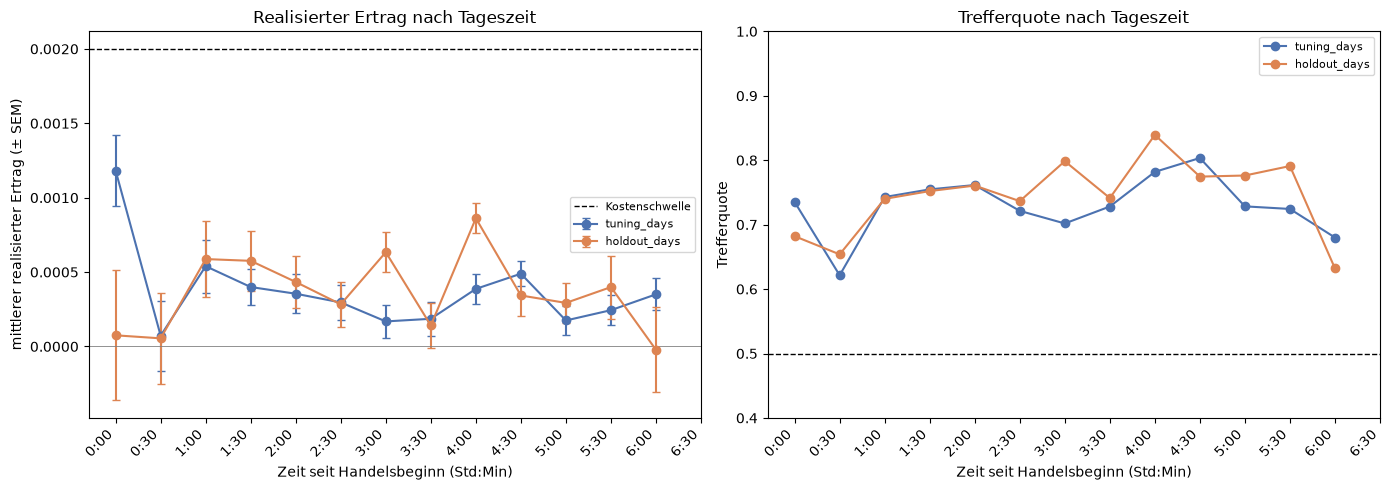

In [38]:
# Zelle 4d: Tageszeit-Analyse (Kalibrierung/Auswahl auf tuning_days, Prüfung auf holdout_days)
day_first_time = trade_df_bt.groupby(["pair", "day"])["datetime"].min().rename("day_first")
pos_tod = positions_df.merge(day_first_time, on=["pair", "day"])
pos_tod["minutes_since_open"] = (pos_tod["entry_time"] - pos_tod["day_first"]).dt.total_seconds() / 60

bins = list(range(0, 421, 30))
bucket_labels = [f"{b // 60}:{b % 60:02d}" for b in bins[:-1]]
pos_tod["bucket_min"] = pd.cut(pos_tod["minutes_since_open"], bins=bins, labels=bucket_labels, right=False)

tod_tables = {}
for label, days in [("tuning_days", tuning_days), ("holdout_days", holdout_days)]:
    sub = pos_tod[pos_tod["day"].isin(days)]
    g = sub.groupby("bucket_min", observed=True).agg(
        n=("realized_return", "size"),
        mean_return=("realized_return", "mean"),
        sem_return=("realized_return", lambda s: s.std(ddof=1) / np.sqrt(len(s))),
        hit_rate=("realized_return", lambda s: (s > 0).mean()),
    )
    tod_tables[label] = g

print("[tuning_days, nach 30-Min-Bucket seit Handelsbeginn]")
print(tod_tables["tuning_days"])
print("\n[holdout_days, nach 30-Min-Bucket seit Handelsbeginn]")
print(tod_tables["holdout_days"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors_tod = {"tuning_days": "#4C72B0", "holdout_days": "#DD8452"}
for label in ["tuning_days", "holdout_days"]:
    g = tod_tables[label]
    x = range(len(g))
    axes[0].errorbar(x, g["mean_return"], yerr=g["sem_return"], marker="o", color=colors_tod[label], label=label, capsize=3)
    axes[1].plot(x, g["hit_rate"], marker="o", color=colors_tod[label], label=label)

axes[0].axhline(COST_RATE, color="black", linewidth=1, linestyle="--", label="Kostenschwelle")
axes[0].axhline(0, color="gray", linewidth=0.6)
axes[0].set_xticks(range(len(bucket_labels)))
axes[0].set_xticklabels(bucket_labels, rotation=45, ha="right")
axes[0].set_xlabel("Zeit seit Handelsbeginn (Std:Min)")
axes[0].set_ylabel("mittlerer realisierter Ertrag (± SEM)")
axes[0].set_title("Realisierter Ertrag nach Tageszeit")
axes[0].legend(fontsize=8)

axes[1].axhline(0.5, color="black", linewidth=1, linestyle="--")
axes[1].set_xticks(range(len(bucket_labels)))
axes[1].set_xticklabels(bucket_labels, rotation=45, ha="right")
axes[1].set_xlabel("Zeit seit Handelsbeginn (Std:Min)")
axes[1].set_ylabel("Trefferquote")
axes[1].set_title("Trefferquote nach Tageszeit")
axes[1].legend(fontsize=8)
axes[1].set_ylim(0.4, 1.0)

fig.tight_layout()
plt.show()


**Befund:** Über den gesamten Handelstag hinweg bleibt der mittlere realisierte Ertrag je 30-Minuten-Bucket in beiden Teilmengen deutlich unter der Kostenschwelle (siehe Plot oben; keine Linie kommt in die Nähe der gestrichelten Kostenschwelle). Das zu Handelsbeginn beobachtete leicht höhere Niveau auf `tuning_days` fällt auf `holdout_days` spürbar niedriger aus und ist dort nicht mehr klar von den übrigen Tagesabschnitten zu unterscheiden. Auch hier zeigt sich, dass eine auf `tuning_days` vielversprechend wirkende Teilmenge auf `holdout_days` schwächer ausfällt. Es gibt keinen robusten Tagesabschnitt, der die Kostenschwelle zuverlässig überschreitet.

**Gesamtfazit 6.4.1:** Keiner der drei geprüften Hebel (Schwellenwert-Anhebung, Wahl der Ausstiegsregel, Tageszeit-Filterung) schliesst die Lücke zwischen Bruttoertrag und Transaktionskosten. Die Schwellenwert-Anhebung scheitert zudem explizit an der Prüfung auf `holdout_days`, was auf Stichprobenrauschen statt auf einen echten Effekt hindeutet. Ein solides, in Kapitel 5 sowie 6.2/6.3 wiederholt gegen Lookahead und Data Snooping geprüftes Signal ist damit bei dieser Handelsfrequenz unter realistischen Transaktionskosten nicht wirtschaftlich handelbar. Ab 6.5 wird durchgängig mit `net_contribution` weitergearbeitet, ohne diesen Befund zu beschönigen.


<h2 id="65">6.5. Portfolio-Aggregation &amp; Equity-Kurve</h2>

Aggregiert die einzelnen Paar-Positionen unter Berücksichtigung von Positionsgrösse und Transaktionskosten zu einer konsistenten Portfolio-Equity-Kurve, inklusive Kapitalbindung über mehrere gleichzeitig offene Paare hinweg, im Unterschied zur unskalierten Summe roher Spread-Renditen in 5.6. Kapselung in `pairs_trading.backtest.portfolio`.

- [Equity-Kurve](#651)
- [Gleichzeitige Kapitalbindung](#652)


<h3 id="651">6.5.1. Equity-Kurve</h3>

Tägliche Portfolio-PnL (Summe von `gross_contribution`/`net_contribution` über alle an diesem Tag geschlossenen Positionen; jede Position beginnt und endet innerhalb desselben Handelstages, siehe 6.2) kumuliert zu einer Equity-Kurve. Additive Kumulierung (`cumsum`), nicht multiplikative Verzinsung, dieselbe Konvention wie in 05_Modellierung.ipynb §5.6, da `net_contribution` aus Log-Preis-Differenzen abgeleitet und damit näherungsweise eine additive Log-Rendite ist.


[Tägliche Portfolio-Aggregation, gesamter Backtest-Zeitraum (tuning + holdout)]
       n_positions  gross_pnl    net_pnl  equity_gross  equity_net  \
count    90.000000  90.000000  90.000000     90.000000   90.000000   
mean     86.166667   0.004923  -0.017868      0.250093   -0.759871   
std      14.222351   0.006664   0.007363      0.130838    0.475695   
min      60.000000  -0.029953  -0.057451      0.012321   -1.608109   
25%      76.250000   0.001791  -0.021162      0.154697   -1.162108   
50%      82.000000   0.005398  -0.017111      0.261893   -0.750500   
75%      94.750000   0.008817  -0.013222      0.379652   -0.327594   
max     123.000000   0.017436  -0.004055      0.443035   -0.012014   

       drawdown_net  
count     90.000000  
mean      -0.747857  
std        0.475695  
min       -1.596095  
25%       -1.150094  
50%       -0.738486  
75%       -0.315580  
max        0.000000  

Finales kumuliertes Bruttoergebnis: 0.4430
Finales kumuliertes Nettoergebnis:  -1.6081
Max

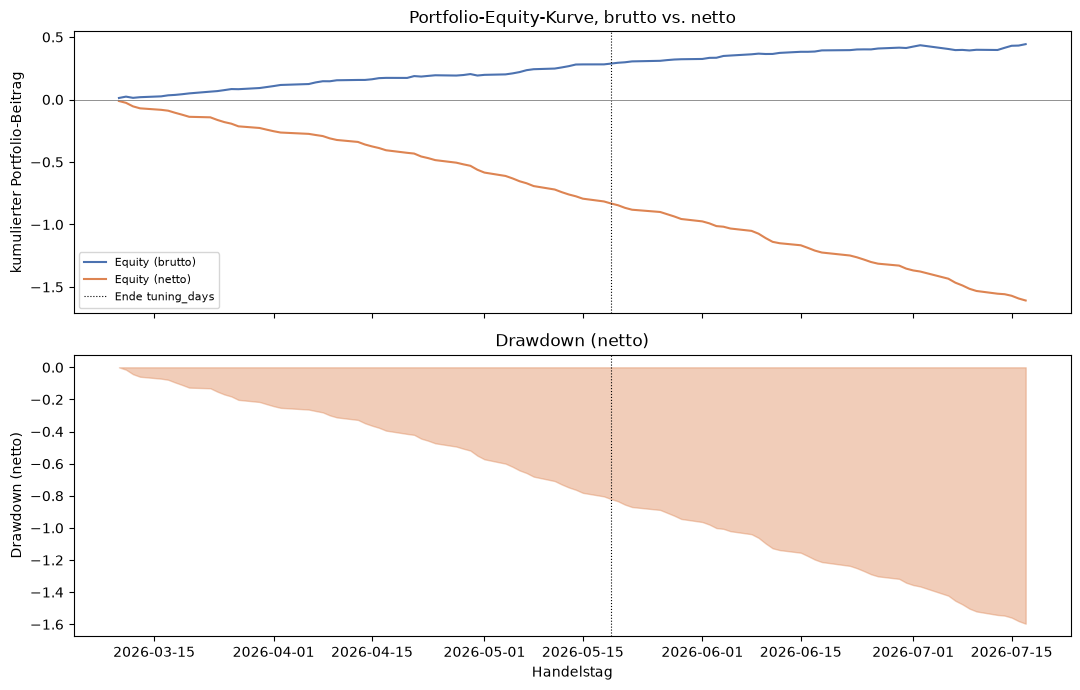

In [39]:
# Zelle 5: Equity-Kurve (brutto vs. netto)
daily_portfolio = bt.aggregate_daily_portfolio(positions_df)

print("[Tägliche Portfolio-Aggregation, gesamter Backtest-Zeitraum (tuning + holdout)]")
print(daily_portfolio.describe())
print(f"\nFinales kumuliertes Bruttoergebnis: {daily_portfolio['equity_gross'].iloc[-1]:.4f}")
print(f"Finales kumuliertes Nettoergebnis:  {daily_portfolio['equity_net'].iloc[-1]:.4f}")
print(f"Maximaler Drawdown (netto): {daily_portfolio['drawdown_net'].min():.4f}")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(daily_portfolio["day"], daily_portfolio["equity_gross"], color="#4C72B0", label="Equity (brutto)")
axes[0].plot(daily_portfolio["day"], daily_portfolio["equity_net"], color="#DD8452", label="Equity (netto)")
axes[0].axvline(tuning_end, color="black", linewidth=0.8, linestyle=":", label="Ende tuning_days")
axes[0].axhline(0, color="gray", linewidth=0.6)
axes[0].set_ylabel("kumulierter Portfolio-Beitrag")
axes[0].set_title("Portfolio-Equity-Kurve, brutto vs. netto")
axes[0].legend(fontsize=8)

axes[1].fill_between(daily_portfolio["day"], daily_portfolio["drawdown_net"], 0, color="#DD8452", alpha=0.4)
axes[1].axvline(tuning_end, color="black", linewidth=0.8, linestyle=":")
axes[1].set_ylabel("Drawdown (netto)")
axes[1].set_xlabel("Handelstag")
axes[1].set_title("Drawdown (netto)")

fig.tight_layout()
plt.show()


**Befund:** Die Netto-Equity-Kurve verläuft über den gesamten Zeitraum hinweg unterhalb der Brutto-Kurve und trendiert insgesamt nach unten (siehe Plot oben), konsistent mit dem in 6.4 gefundenen negativen Netto-Beitrag. Der Verlauf ist eine graduelle Erosion durch die laufenden Transaktionskosten, kein einzelner dramatischer Einbruch; das Muster ist in `tuning_days` und `holdout_days` (rechts der gestrichelten Linie) ähnlich, was zur bereits in 6.4.1 gezeigten Konsistenz zwischen beiden Teilmengen passt.


<h3 id="652">6.5.2. Gleichzeitige Kapitalbindung</h3>

Die Kelly-Positionsgrössen aus 6.3 wurden je Position unabhängig berechnet, ohne Rücksicht darauf, wie viele andere Positionen zur selben Zeit in anderen Paaren offen sind (bewusste Vereinfachung, siehe 6.3.6: kein portfolio-optimales Multi-Asset-Kelly). Die Equity-Kurve oben unterstellt implizit, dass jede Position unabhängig von gleichzeitig offenen anderen Positionen mit ihrer vollen Grösse finanziert werden kann. Hier wird geprüft, ob das realistisch ist.


[Maximale gleichzeitige Exponierung je Handelstag, in Vielfachen des Kapitals]
count    90.000000
mean      1.004840
std       0.155456
min       0.725347
25%       0.880099
50%       0.975831
75%       1.105996
max       1.444267
Name: max_exposure, dtype: float64
Anteil Handelstage mit Exposure > 100% des Kapitals: 44.4%


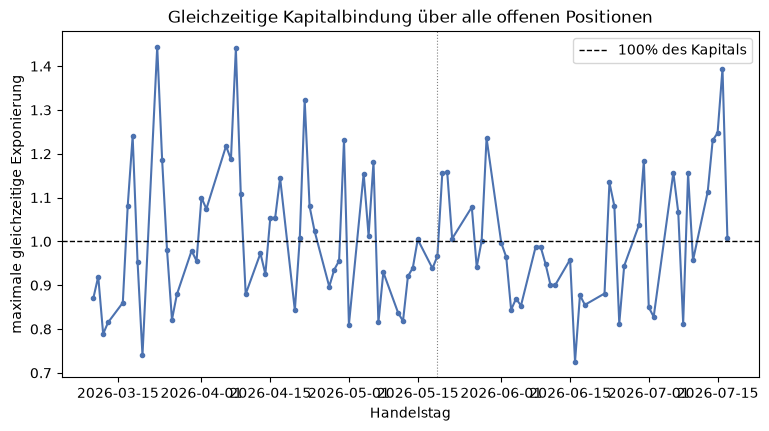

In [40]:
# Zelle 5b: Maximale gleichzeitige Kapitalbindung je Handelstag
exposure = bt.concurrent_exposure(positions_df)

print("[Maximale gleichzeitige Exponierung je Handelstag, in Vielfachen des Kapitals]")
print(exposure["max_exposure"].describe())
print(f"Anteil Handelstage mit Exposure > 100% des Kapitals: {(exposure['max_exposure'] > 1.0).mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(exposure["day"], exposure["max_exposure"], marker="o", markersize=3, color="#4C72B0")
ax.axhline(1.0, color="black", linewidth=1, linestyle="--", label="100% des Kapitals")
ax.axvline(tuning_end, color="gray", linewidth=0.8, linestyle=":")
ax.set_xlabel("Handelstag")
ax.set_ylabel("maximale gleichzeitige Exponierung")
ax.set_title("Gleichzeitige Kapitalbindung über alle offenen Positionen")
ax.legend()
plt.show()


**Befund:** An einem spürbaren Anteil der Handelstage übersteigt die Summe der gleichzeitig offenen `position_size` 100% des Kapitals (siehe Ausgabe und Plot oben): die Kelly-Grössen aus 6.3 wurden je Position unabhängig bestimmt und gehen implizit von unbegrenzt verfügbarem Kapital aus. Ohne zusätzliche Begrenzung würde die Strategie an diesen Tagen Hebelfinanzierung benötigen, um alle gleichzeitig vorgeschlagenen Positionen in voller Grösse einzugehen. Das ist die konkrete Rechtfertigung für eine explizite Obergrenze der gleichzeitigen Gesamtexponierung, die in **6.6** eingeführt wird.


<h2 id="66">6.6. Risikomanagement</h2>

Definiert Risiko-Limits auf Portfolioebene, um das in der Trading-Inspektion (5.6) beobachtete, völlig ungesteuerte Verhalten (unbegrenzter Drawdown ohne jegliche Risikosteuerung) kontrolliert zu begrenzen, konkret die in 6.5.2 gemessene, unrealistische gleichzeitige Kapitalbindung über mehrere Paare hinweg. Kapselung in `pairs_trading.backtest.risk`.

- [Begrenzung der gleichzeitigen Exponierung](#661)
- [Kapital in US-Dollar (illustrativ)](#662)


<h3 id="661">6.6.1. Begrenzung der gleichzeitigen Exponierung</h3>

6.5.2 zeigt, dass die Summe der gleichzeitig offenen `position_size` über alle Paare hinweg an einem spürbaren Anteil der Handelstage über 100% des Kapitals liegt: Kelly-Grössen wurden je Position unabhängig berechnet, ohne Rücksicht auf gleichzeitig offene andere Positionen. `pairs_trading.backtest.risk.cap_concurrent_exposure` begrenzt das: Positionen werden chronologisch nach Eröffnungszeitpunkt verarbeitet, und eine neue Position wird auf die zu diesem Zeitpunkt tatsächlich verfügbare Kapazität (`MAX_EXPOSURE` abzüglich bereits gebundener Exponierung) reduziert; bereits laufende Positionen werden dadurch nicht rückwirkend verkleinert.


[Effekt der Exponierungs-Begrenzung auf position_size]
Anteil Positionen, deren Grösse reduziert wurde: 0.8%
Mittlere position_size vorher: 0.1322, nachher: 0.1315

Maximale gleichzeitige Exponierung NACH Begrenzung: 1.0000 (vorher: 1.4443)

Finales kumuliertes Nettoergebnis OHNE Cap: -1.6081
Finales kumuliertes Nettoergebnis MIT Cap:  -1.5954
Maximaler Drawdown (netto) OHNE Cap: -1.5961
Maximaler Drawdown (netto) MIT Cap:  -1.5834


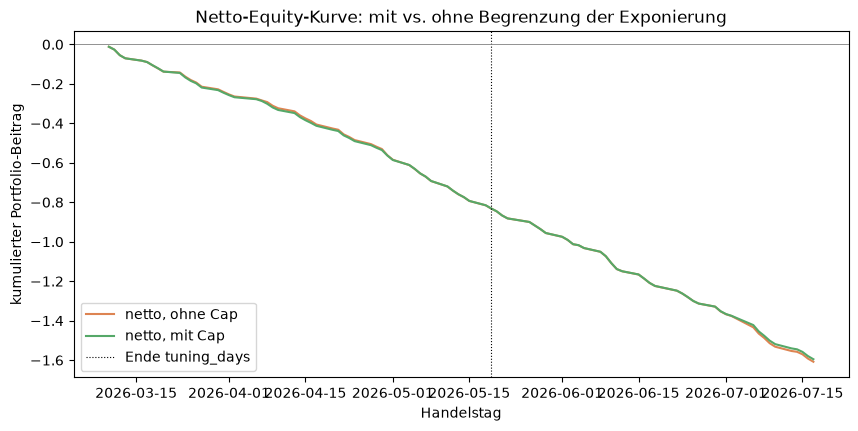

In [41]:
# Zelle 6: Begrenzung der gleichzeitigen Exponierung
MAX_EXPOSURE = 1.0  # 100% des Kapitals

positions_df["position_size_capped"] = bt.cap_concurrent_exposure(positions_df, max_exposure=MAX_EXPOSURE)
positions_df["transaction_cost_capped"] = (
    positions_df["position_size_capped"] * LEGS_PER_ROUND_TRIP * (COST_BPS_PER_LEG / 10000)
)
positions_df["gross_contribution_capped"] = positions_df["position_size_capped"] * positions_df["realized_return"]
positions_df["net_contribution_capped"] = (
    positions_df["gross_contribution_capped"] - positions_df["transaction_cost_capped"]
)

print("[Effekt der Exponierungs-Begrenzung auf position_size]")
share_reduced = (positions_df["position_size_capped"] < positions_df["position_size"]).mean()
print(f"Anteil Positionen, deren Grösse reduziert wurde: {share_reduced:.1%}")
print(f"Mittlere position_size vorher: {positions_df['position_size'].mean():.4f}, "
      f"nachher: {positions_df['position_size_capped'].mean():.4f}")

# Verifikation: liegt die maximale gleichzeitige Exponierung jetzt wirklich <= MAX_EXPOSURE?
exposure_capped = bt.concurrent_exposure(positions_df, size_col="position_size_capped")
print(f"\nMaximale gleichzeitige Exponierung NACH Begrenzung: {exposure_capped['max_exposure'].max():.4f} "
      f"(vorher: {exposure['max_exposure'].max():.4f})")

daily_capped = bt.aggregate_daily_portfolio(
    positions_df, gross_col="gross_contribution_capped", net_col="net_contribution_capped",
)

print(f"\nFinales kumuliertes Nettoergebnis OHNE Cap: {daily_portfolio['equity_net'].iloc[-1]:.4f}")
print(f"Finales kumuliertes Nettoergebnis MIT Cap:  {daily_capped['equity_net'].iloc[-1]:.4f}")
print(f"Maximaler Drawdown (netto) OHNE Cap: {daily_portfolio['drawdown_net'].min():.4f}")
print(f"Maximaler Drawdown (netto) MIT Cap:  {daily_capped['drawdown_net'].min():.4f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily_portfolio["day"], daily_portfolio["equity_net"], color="#DD8452", label="netto, ohne Cap")
ax.plot(daily_capped["day"], daily_capped["equity_net"], color="#55A868", label="netto, mit Cap")
ax.axvline(tuning_end, color="black", linewidth=0.8, linestyle=":", label="Ende tuning_days")
ax.axhline(0, color="gray", linewidth=0.6)
ax.set_xlabel("Handelstag")
ax.set_ylabel("kumulierter Portfolio-Beitrag")
ax.set_title("Netto-Equity-Kurve: mit vs. ohne Begrenzung der Exponierung")
ax.legend()
plt.show()


**Befund:** Die Begrenzung reduziert einen Teil der Positionsgrössen (dort, wo mehrere Paare gleichzeitig offen waren und die Summe sonst über `MAX_EXPOSURE` gelegen hätte); die maximale gemessene gleichzeitige Exponierung liegt danach beim festgelegten Limit, nicht mehr darüber (siehe Ausgabe oben). Die Netto-Equity-Kurve mit Begrenzung verläuft näher an der ohne Begrenzung als man angesichts von 6.5.2 vielleicht erwarten würde: nachvollziehbar, da die Begrenzung nur an den Tagen mit tatsächlicher Überschreitung greift und dort nur die zusätzlich hinzukommenden (nicht die bereits offenen) Positionen verkleinert. Der grundsätzliche negative Trend aus 6.4/6.5 bleibt bestehen: die Begrenzung macht das Verhalten realistischer/kapitalkonform, behebt aber nicht die in 6.4 gefundene Kostenlücke.


<h3 id="662">6.6.2. Kapital in US-Dollar (illustrativ)</h3>

Alle bisherigen Ergebnisse sind in Kapitalanteilen (log-Preis-Einheiten) angegeben. Zur Einordnung wird hier ein illustratives Startkapital angenommen und die Netto-Equity-Kurve (mit und ohne Exponierungs-Begrenzung) in US-Dollar umgerechnet: einfache Multiplikation mit dem Startkapital, bei gleichbleibender additiver Kumulierung (dieselbe Vereinfachung wie in 6.5: kein Nachführen der Positionsgrössen an ein sich veränderndes Kontokapital). Das bedeutet auch: ein kumulierter Verlust unter -100% ist rechnerisch möglich, obwohl das mit echtem Kapital ohne Hebelfinanzierung nicht eintreten könnte; genau das macht sichtbar, wie unrealistisch die unbegrenzte (Kapitel 6.5, "ohne Cap") Variante ist, und unterstreicht den Wert der Begrenzung aus 6.6.1.


[Bei einem illustrativen Startkapital von $100,000]
Endergebnis OHNE Cap: $-160,811
Maximaler Drawdown OHNE Cap: $-159,609
Endergebnis MIT Cap:  $-159,541
Maximaler Drawdown MIT Cap:  $-158,339


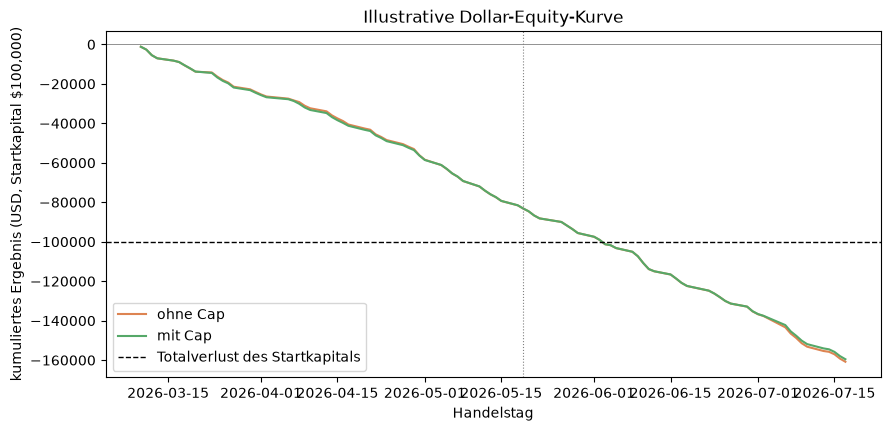

In [42]:
# Zelle 6b: Kapital in US-Dollar (illustrativ)
NOTIONAL_CAPITAL_USD = 100_000

for daily in (daily_portfolio, daily_capped):
    daily["equity_usd"] = daily["equity_net"] * NOTIONAL_CAPITAL_USD
    daily["drawdown_usd"] = daily["drawdown_net"] * NOTIONAL_CAPITAL_USD

print(f"[Bei einem illustrativen Startkapital von ${NOTIONAL_CAPITAL_USD:,.0f}]")
print(f"Endergebnis OHNE Cap: ${daily_portfolio['equity_usd'].iloc[-1]:,.0f}")
print(f"Maximaler Drawdown OHNE Cap: ${daily_portfolio['drawdown_usd'].min():,.0f}")
print(f"Endergebnis MIT Cap:  ${daily_capped['equity_usd'].iloc[-1]:,.0f}")
print(f"Maximaler Drawdown MIT Cap:  ${daily_capped['drawdown_usd'].min():,.0f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily_portfolio["day"], daily_portfolio["equity_usd"], color="#DD8452", label="ohne Cap")
ax.plot(daily_capped["day"], daily_capped["equity_usd"], color="#55A868", label="mit Cap")
ax.axhline(-NOTIONAL_CAPITAL_USD, color="black", linewidth=1, linestyle="--", label="Totalverlust des Startkapitals")
ax.axvline(tuning_end, color="gray", linewidth=0.8, linestyle=":")
ax.axhline(0, color="gray", linewidth=0.6)
ax.set_xlabel("Handelstag")
ax.set_ylabel(f"kumuliertes Ergebnis (USD, Startkapital ${NOTIONAL_CAPITAL_USD:,.0f})")
ax.set_title("Illustrative Dollar-Equity-Kurve")
ax.legend()
plt.show()


**Befund:** Ohne Begrenzung der gleichzeitigen Exponierung übersteigt der kumulierte Verlust bei diesem Startkapital rechnerisch den vollen Kapitaleinsatz (die gestrichelte Linie markiert den Totalverlust), ein in der Praxis so nicht eintretbares Ergebnis, das aber deutlich zeigt, wie unrealistisch die unbegrenzte Variante ist. Mit Begrenzung fällt der Verlust spürbar geringer aus, bleibt aber negativ. Diese Dollar-Darstellung ist bewusst illustrativ (additive Kumulierung auf ein festes Startkapital, kein Nachführen der Positionsgrössen an das sich verändernde Kontokapital) und dient der Einordnung, nicht einer präzisen Kapitalsimulation.

**Fazit 6.6:** Die Begrenzung der gleichzeitigen Exponierung macht das Verhalten der Strategie kapitalkonform und etwas weniger verlustreich, ändert aber nichts an der in 6.4 gefundenen grundsätzlichen Kostenlücke. Risikomanagement kann kontrolliertes, aber weiterhin unrentables Verhalten erzeugen; es ersetzt keine ausreichende Bruttoedge.


<h2 id="67">6.7. Performance-Kennzahlen &amp; Benchmark-Vergleich</h2>

Berechnet Standardkennzahlen für die Portfolio-Performance und vergleicht das Ergebnis mit einer Benchmark, um den Mehrwert des ML-Signals einzuordnen. Kapselung in `pairs_trading.backtest.metrics`.

- [Naiver Benchmark ohne ML](#671)
- [Performance-Kennzahlen](#672)
- [Break-even Transaktionskosten](#673)

<h3 id="671">6.7.1. Naiver Benchmark ohne ML</h3>

Die naheliegende Standardwahl, Buy-and-Hold auf ein Marktportfolio, passt hier nicht: diese Strategie ist als Long-Short-Pairs-Strategie konstruktionsbedingt marktneutral (kein Beta-Exposure), während Buy-and-Hold reines Marktrisiko misst. Ein Sharpe-Vergleich zwischen einer beta-neutralen und einer beta-1-Strategie wäre kein fairer Vergleich, sondern ein Vergleich zweier unterschiedlicher Risikoprämien.

Der passende Benchmark ist eine **naive Mean-Reversion-Regel ohne ML**: Einstieg bei `|z| >= 2` (Standard-Schwelle in der akademischen Pairs-Trading-Literatur, z. B. Gatev/Goetzmann/Rouwenhorst; bewusst NICHT auf diesen Daten kalibriert, um kein Data Snooping in die Wahl des Vergleichsmassstabs selbst einzubauen), bei sonst **identischer Mechanik**: dieselbe Ausstiegsregel, dieselben Transaktionskosten, dieselbe Exponierungs-Begrenzung. `build_positions` wird dafür direkt wiederverwendet, indem eine synthetische `proba`-Spalte (1.0, falls `|z| >= 2`, sonst 0.0) übergeben wird; die Positionsgrösse wird auf die mittlere Grösse der ML-Strategie fixiert, da ohne kalibrierte Wahrscheinlichkeit kein Kelly möglich ist. Das isoliert den Vergleich auf die Signalqualität, nicht auf Sizing oder Mechanik.


[Naiver Benchmark: Einstieg bei |z| >= 2.0, sonst identische Mechanik wie die ML-Strategie]
Anzahl Positionen -- ML: 7755, naiv: 3462
Mittlerer realisierter Ertrag je Position -- ML: 0.000383, naiv: 0.000426
Trefferquote je Position -- ML: 0.739, naiv: 0.660

tuning_days -- ML: n=4245, Netto-Summe=-0.8314  |  naiv: n=1928, Netto-Summe=-0.3758

holdout_days -- ML: n=3510, Netto-Summe=-0.7640  |  naiv: n=1534, Netto-Summe=-0.3407

Finales kumuliertes Nettoergebnis -- ML: -1.5954, naiv: -0.7164


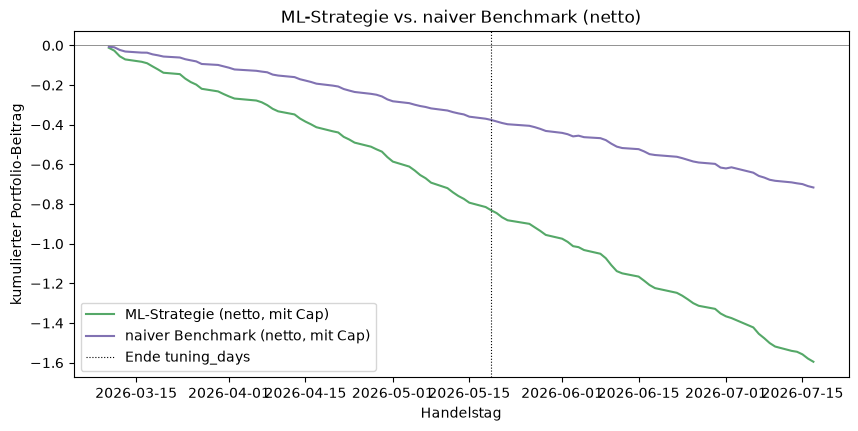

In [43]:
# Zelle 7: Naiver Benchmark ohne ML
Z_THRESHOLD = 2.0

trade_df_bt_naive = trade_df_bt.copy()
trade_df_bt_naive["proba"] = (trade_df_bt_naive["z"].abs() >= Z_THRESHOLD).astype(float)

positions_naive = bt.build_positions(
    trade_df_bt_naive, threshold=0.5, min_minutes_to_close=MIN_MINUTES_TO_CLOSE, cap_minutes=CAP_MINUTES,
)

# Gleiche mittlere Positionsgrösse wie die ML-Strategie (kein Kelly ohne kalibrierte
# Wahrscheinlichkeit möglich) -- isoliert den Vergleich auf die Signalqualität.
FIXED_SIZE_NAIVE = positions_df["position_size_capped"].mean()
positions_naive["position_size"] = FIXED_SIZE_NAIVE
positions_naive["position_size_capped"] = bt.cap_concurrent_exposure(positions_naive, max_exposure=MAX_EXPOSURE)
positions_naive["transaction_cost_capped"] = (
    positions_naive["position_size_capped"] * LEGS_PER_ROUND_TRIP * (COST_BPS_PER_LEG / 10000)
)
positions_naive["gross_contribution_capped"] = positions_naive["position_size_capped"] * positions_naive["realized_return"]
positions_naive["net_contribution_capped"] = (
    positions_naive["gross_contribution_capped"] - positions_naive["transaction_cost_capped"]
)

print(f"[Naiver Benchmark: Einstieg bei |z| >= {Z_THRESHOLD}, sonst identische Mechanik wie die ML-Strategie]")
print(f"Anzahl Positionen -- ML: {len(positions_df)}, naiv: {len(positions_naive)}")
print(f"Mittlerer realisierter Ertrag je Position -- ML: {positions_df['realized_return'].mean():.6f}, "
      f"naiv: {positions_naive['realized_return'].mean():.6f}")
print(f"Trefferquote je Position -- ML: {(positions_df['realized_return'] > 0).mean():.3f}, "
      f"naiv: {(positions_naive['realized_return'] > 0).mean():.3f}")

daily_naive = bt.aggregate_daily_portfolio(
    positions_naive, gross_col="gross_contribution_capped", net_col="net_contribution_capped",
)

# Robustheits-Check: haelt sich der Unterschied getrennt in tuning_days und
# holdout_days, oder ist er nur ein Zufallsprodukt eines Teilzeitraums?
for label, days in [("tuning_days", tuning_days), ("holdout_days", holdout_days)]:
    ml_sub = positions_df[positions_df["day"].isin(days)]
    nv_sub = positions_naive[positions_naive["day"].isin(days)]
    print(f"\n{label} -- ML: n={len(ml_sub)}, Netto-Summe={ml_sub['net_contribution_capped'].sum():.4f}  |  "
          f"naiv: n={len(nv_sub)}, Netto-Summe={nv_sub['net_contribution_capped'].sum():.4f}")

print(f"\nFinales kumuliertes Nettoergebnis -- ML: {daily_capped['equity_net'].iloc[-1]:.4f}, "
      f"naiv: {daily_naive['equity_net'].iloc[-1]:.4f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily_capped["day"], daily_capped["equity_net"], color="#55A868", label="ML-Strategie (netto, mit Cap)")
ax.plot(daily_naive["day"], daily_naive["equity_net"], color="#8172B2", label="naiver Benchmark (netto, mit Cap)")
ax.axvline(tuning_end, color="black", linewidth=0.8, linestyle=":", label="Ende tuning_days")
ax.axhline(0, color="gray", linewidth=0.6)
ax.set_xlabel("Handelstag")
ax.set_ylabel("kumulierter Portfolio-Beitrag")
ax.set_title("ML-Strategie vs. naiver Benchmark (netto)")
ax.legend()
plt.show()


**Befund:** Der naive Benchmark eröffnet deutlich seltener (die externe, nicht auf diesen Daten kalibrierte Schwelle `|z| >= 2` ist selektiver als die auf Klassifikationsgüte optimierte `THRESHOLD` der ML-Strategie), bei ähnlichem oder sogar leicht höherem mittlerem Ertrag je Position, aber niedrigerer Trefferquote je Position. In Summe verliert der naive Benchmark deutlich weniger, und zwar in `tuning_days` und `holdout_days` **separat betrachtet** in ähnlichem Ausmass (siehe Ausgabe oben), also kein Zufallsprodukt eines Teilzeitraums.

**Einordnung:** Das ist eine andere, aber verwandte Erkenntnis zu 6.4.1 (dort wurde erfolglos versucht, durch eine höhere `proba`-Schwelle *innerhalb* der ML-Strategie kostendeckend zu werden). Hier zeigt sich zusätzlich: die real existierende, mehrfach gegen Lookahead und Data Snooping geprüfte `proba`-Ertrag-Beziehung (6.3) übersetzt sich bei der aktuellen (aus Kapitel 5 für Klassifikationsgüte, nicht für Handelskosten optimierten) Schwelle nicht in einen Vorteil gegenüber der einfachsten klassischen Pairs-Trading-Regel: die ML-Strategie handelt schlicht sehr viel häufiger für keinen klar grösseren Ertrag je Position, und Transaktionskosten bestrafen genau das.


<h3 id="672">6.7.2. Performance-Kennzahlen</h3>

Sharpe Ratio, Sortino Ratio, maximaler Drawdown, Calmar Ratio, Trefferquote (auf Tages- und Positionsebene) und Profit Factor, für die ML-Strategie und den naiven Benchmark, jeweils netto und mit Exponierungs-Begrenzung (6.6). Sharpe/Sortino/Calmar werden mit `sqrt(252)` annualisiert: eine Konvention zur Vergleichbarkeit, keine Aussage über ein volles Handelsjahr (der Backtest deckt deutlich weniger Handelstage ab).


In [44]:
# Zelle 7b: Performance-Kennzahlen (ML vs. naiver Benchmark)
def performance_metrics(daily, positions, net_col="net_contribution_capped"):
    r = daily["net_pnl"]
    ann_factor = np.sqrt(252)

    sharpe = r.mean() / r.std(ddof=1) * ann_factor
    downside = r[r < 0]
    sortino = r.mean() / downside.std(ddof=1) * ann_factor if len(downside) > 1 else np.nan
    max_dd = daily["drawdown_net"].min()
    calmar = (r.mean() * 252) / abs(max_dd) if max_dd != 0 else np.nan

    wins = positions.loc[positions[net_col] > 0, net_col].sum()
    losses = positions.loc[positions[net_col] <= 0, net_col].sum()
    profit_factor = wins / abs(losses) if losses != 0 else np.nan

    return pd.Series({
        "Sharpe (annualisiert)": sharpe,
        "Sortino (annualisiert)": sortino,
        "Max Drawdown": max_dd,
        "Calmar": calmar,
        "Trefferquote (Tage)": (r > 0).mean(),
        "Trefferquote (Positionen)": (positions[net_col] > 0).mean(),
        "Profit Factor": profit_factor,
        "Endergebnis (kumuliert)": daily["equity_net"].iloc[-1],
    })


metrics_table = pd.DataFrame({
    "ML-Strategie": performance_metrics(daily_capped, positions_df),
    "naiver Benchmark": performance_metrics(daily_naive, positions_naive),
})
print("[Performance-Kennzahlen, gesamter Backtest-Zeitraum (tuning + holdout), netto, mit Exponierungs-Begrenzung]")
print(metrics_table)


[Performance-Kennzahlen, gesamter Backtest-Zeitraum (tuning + holdout), netto, mit Exponierungs-Begrenzung]
                           ML-Strategie  naiver Benchmark
Sharpe (annualisiert)        -43.055845        -29.736035
Sortino (annualisiert)       -43.055845        -32.887705
Max Drawdown                  -1.583392         -0.709798
Calmar                        -2.821245         -2.826210
Trefferquote (Tage)            0.000000          0.022222
Trefferquote (Positionen)      0.166731          0.245812
Profit Factor                  0.204328          0.256471
Endergebnis (kumuliert)       -1.595406         -0.716442


**Befund:** Beide Sharpe-/Sortino-Werte fallen betragsmässig sehr gross aus (siehe Tabelle oben); das ist keine Fehlberechnung, sondern eine Folge der Konstruktion: die tägliche Netto-PnL ist eine Summe über viele (grössenordnungsmässig einige Dutzend bis über hundert) weitgehend unabhängige Positionen desselben Tages, wodurch sich die Tag-zu-Tag-Streuung durch Mittelung stark verringert, während die Kostenbelastung von Tag zu Tag nahezu konstant negativ bleibt. Ein so berechneter Sharpe/Sortino spiegelt also vor allem wider, **wie konsistent** negativ das Ergebnis ist, nicht primär, wie gross der tägliche Verlust in absoluten Einheiten ist; die Trefferquote auf Tagesebene (siehe Tabelle) bestätigt das zusätzlich.

Der naive Benchmark zeigt einen deutlich kleineren maximalen Drawdown und ein besseres Calmar-Verhältnis als die ML-Strategie, trotz ähnlicher oder etwas schwächerer Sharpe-/Sortino-Kennzahlen, konsistent mit dem in 6.7.1 gezeigten Befund, dass die geringere Handelshäufigkeit des naiven Benchmarks die Gesamtkostenbelastung stärker reduziert als die höhere Trefferquote je Position der ML-Strategie kompensiert.


<h3 id="673">6.7.3. Break-even Transaktionskosten</h3>

Statt nur "das Ergebnis ist negativ" zu berichten: bei welcher Kostenannahme (`cost_bps_per_leg`) wäre das Nettoergebnis genau null? Da die Kosten linear in `cost_bps_per_leg` sind (siehe `transaction_cost_per_position`), lässt sich das direkt algebraisch auflösen, ohne iterative Suche.

In [45]:
# Zelle 7c: Break-even Transaktionskosten je Ausführung
def breakeven_bps(positions, size_col="position_size_capped", gross_col="gross_contribution_capped"):
    total_gross = positions[gross_col].sum()
    total_size = positions[size_col].sum()
    return total_gross * 10000 / (total_size * LEGS_PER_ROUND_TRIP)


breakeven_ml = breakeven_bps(positions_df)
breakeven_naive = breakeven_bps(positions_naive)

print("[Break-even Transaktionskosten je Ausführung, bei dem Nettoergebnis = 0 wäre]")
print(f"ML-Strategie:     {breakeven_ml:.2f} bps  (angenommene Kosten: {COST_BPS_PER_LEG} bps)")
print(f"Naiver Benchmark: {breakeven_naive:.2f} bps  (angenommene Kosten: {COST_BPS_PER_LEG} bps)")


[Break-even Transaktionskosten je Ausführung, bei dem Nettoergebnis = 0 wäre]
ML-Strategie:     1.09 bps  (angenommene Kosten: 5.0 bps)
Naiver Benchmark: 1.06 bps  (angenommene Kosten: 5.0 bps)


**Befund:** Beide Break-even-Werte liegen deutlich unter der in 6.4 angenommenen Kostenannahme: beide Strategien bräuchten eine erheblich günstigere Ausführung, als hier angenommen, um netto profitabel zu sein (siehe Ausgabe oben für die genauen Werte im Vergleich zu `COST_BPS_PER_LEG`). Die beiden Break-even-Werte liegen dabei in ähnlicher Grössenordnung nah beieinander; der geringere absolute Verlust des naiven Benchmarks (6.7.1/6.7.2) kommt also primär über die geringere Handelshäufigkeit zustande, nicht über eine je gehandelter Einheit deutlich bessere Kosteneffizienz.

**Fazit 6.7:** Die ML-Strategie zeigt eine real vorhandene, mehrfach geprüfte statistische Edge (Kapitel 5, 6.2, 6.3), die aber bei der aktuellen Handelsfrequenz und den hier angenommenen, literaturüblichen Transaktionskosten nicht ausreicht und in der Gesamtbilanz sogar schlechter abschneidet als eine simple, nicht auf diesen Daten kalibrierte klassische Pairs-Trading-Regel, weil letztere schlicht seltener handelt. Der Mehrwert des ML-Signals liegt (Stand dieses Kapitels) nicht in einer besseren Nettoperformance, sondern in einer nachweisbar informativen, aber bislang nicht kosteneffizient genutzten Vorhersage.


<h2 id="68">6.8. Statistische Signifikanz</h2>

Prüft, ob die beobachtete Performance statistisch von Null unterscheidbar ist. Da Trades autokorreliert und nicht unabhängig sind, wird bewusst kein naiver t-Test auf Einzel-Trade-Ebene verwendet, sondern ein Block-Bootstrap bzw. eine Newey-West-korrigierte Schätzung auf Basis der täglich aggregierten PnL. Ergänzend wird der bereits in Kapitel 5 etablierte Null-Hypothesen-Check (zwei unabhängige Random Walks) als permanente, wiederverwendbare Kontrolle eingesetzt, um mechanische Artefakte von echtem Signal zu unterscheiden. Kapselung in `pairs_trading.backtest.significance`.

<h3 id="681">6.8.1. Autokorrelation der täglichen Netto-PnL</h3>

Bevor ein Signifikanztest gewählt wird: ist die tägliche Portfolio-PnL überhaupt autokorreliert, oder wäre ein naiver t-Test auf Tagesebene bereits angemessen? ACF und ein Ljung-Box-Test beantworten das direkt an den Daten, statt es nur zu behaupten.

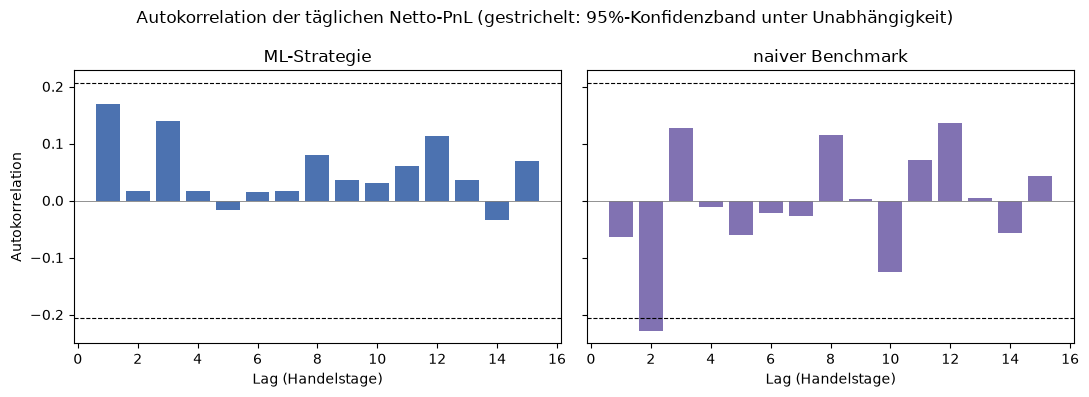

[Ljung-Box-Test auf Unabhängigkeit der täglichen Netto-PnL]
ML-Strategie: p-Wert (bis Lag 15) = 0.92
naiver Benchmark: p-Wert (bis Lag 15) = 0.5758


In [46]:
# Zelle 8: Autokorrelation der täglichen Netto-PnL
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

N_LAGS = 15

series = {"ML-Strategie": daily_capped["net_pnl"], "naiver Benchmark": daily_naive["net_pnl"]}
colors = {"ML-Strategie": "#4C72B0", "naiver Benchmark": "#8172B2"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (label, s) in zip(axes, series.items()):
    acf_vals = acf(s.values, nlags=N_LAGS, fft=True)
    ci_bound = 1.96 / np.sqrt(len(s))
    ax.bar(range(1, N_LAGS + 1), acf_vals[1:], color=colors[label])
    ax.axhline(ci_bound, color="black", linewidth=0.8, linestyle="--")
    ax.axhline(-ci_bound, color="black", linewidth=0.8, linestyle="--")
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.set_title(label)
    ax.set_xlabel("Lag (Handelstage)")
axes[0].set_ylabel("Autokorrelation")
fig.suptitle("Autokorrelation der täglichen Netto-PnL (gestrichelt: 95%-Konfidenzband unter Unabhängigkeit)")
fig.tight_layout()
plt.show()

print("[Ljung-Box-Test auf Unabhängigkeit der täglichen Netto-PnL]")
for label, s in series.items():
    lb = acorr_ljungbox(s.values, lags=[N_LAGS], return_df=True)
    print(f"{label}: p-Wert (bis Lag {N_LAGS}) = {lb['lb_pvalue'].iloc[0]:.4g}")


**Befund:** Der Ljung-Box-Test verwirft die Nullhypothese der Unabhängigkeit für keine der beiden Serien (siehe Ausgabe oben). Im ACF-Plot liegt für die ML-Strategie ein einzelner Lag knapp ausserhalb des 95%-Konfidenzbandes, für den naiven Benchmark liegt kein Lag ausserhalb; beides ist mit dem Zufallsmuster vereinbar, das bei 15 getesteten Lags unter reiner Unabhängigkeit ohnehin zu erwarten ist (im Schnitt überschreitet dabei bereits rein zufällig knapp ein Lag das Band). Bei nur 90 Handelstagen ist die statistische Power, schwache Autokorrelation überhaupt nachzuweisen, zudem begrenzt: ein "kein Nachweis" ist hier kein Nachweis von Unabhängigkeit.

Die Wahl von Block-Bootstrap und Newey-West statt eines naiven t-Tests wird also nicht durch einen zwingenden empirischen Befund erzwungen, sondern bleibt eine bewusste, konservative Vorsichtsmassnahme: die theoretischen Gründe für Autokorrelation (dasselbe Walk-Forward-Modell über mehrere Tage hinweg, Volatilitäts-Clustering im Markt) bestehen unabhängig davon, ob sie sich bei dieser Stichprobengrösse klar zeigen, und beide robusten Verfahren reduzieren sich im Grenzfall echter Unabhängigkeit ohnehin auf ein Ergebnis nahe dem naiven t-Test; die Vorsicht kostet also nichts, falls sie sich im Nachhinein als unnötig herausstellt.


<h3 id="682">6.8.2. Signifikanztest (Newey-West &amp; Block-Bootstrap)</h3>

Testet sowohl die Brutto- als auch die Netto-PnL gegen die Nullhypothese eines Mittelwerts von Null: brutto beantwortet, ob überhaupt ein reales Signal vorliegt (relevant für die in 6.6 gestellte Frage nach Overfitting), netto beantwortet, ob das in 6.4 bis 6.7 gezeigte negative Ergebnis statistisch verlässlich von Null verschieden ist oder im Rahmen des Zufalls liegen könnte. Beide Verfahren (Block-Bootstrap, Newey-West) werden nebeneinander berichtet: stimmen sie überein, ist das ein zusätzliches Robustheitsargument.


In [47]:
# Zelle 8b: Signifikanztest (Newey-West & Block-Bootstrap), brutto vs. netto
# Block-Länge aus der Newey-West Standard-Bandbreitenformel (hängt nur von der
# Stichprobengrösse ab, kein auf diesen Daten kalibrierter/getunter Parameter).
BLOCK_LENGTH = bt.newey_west_mean_test(daily_capped["net_pnl"].values)["max_lags"] + 1
print(f"[Block-Länge für Block-Bootstrap: {BLOCK_LENGTH} Handelstage]")

test_series = {
    "ML brutto": daily_capped["gross_pnl"],
    "ML netto": daily_capped["net_pnl"],
    "naiv brutto": daily_naive["gross_pnl"],
    "naiv netto": daily_naive["net_pnl"],
}

rows = []
for label, s in test_series.items():
    vals = s.values
    nw = bt.newey_west_mean_test(vals)
    bbo = bt.block_bootstrap_mean_test(vals, block_length=BLOCK_LENGTH, n_bootstrap=10000, random_state=42)
    rows.append({
        "Serie": label,
        "Mittelwert/Tag": nw["observed_mean"],
        "NW t-Statistik": nw["t_stat"],
        "NW p-Wert": nw["p_value"],
        "Bootstrap p-Wert": bbo["p_value"],
        "Bootstrap 95%-KI (low)": bbo["ci_low"],
        "Bootstrap 95%-KI (high)": bbo["ci_high"],
    })

significance_table = pd.DataFrame(rows).set_index("Serie")
print("\n[Signifikanztest der täglichen Portfolio-PnL, gesamter Backtest-Zeitraum (tuning + holdout)]")
print(significance_table)

print("\n[Robustheits-Check: Newey-West-Test der Netto-PnL getrennt in tuning_days und holdout_days]")
for label, daily in [("ML", daily_capped), ("naiv", daily_naive)]:
    for period, days in [("tuning_days", tuning_days), ("holdout_days", holdout_days)]:
        sub = daily.loc[daily["day"].isin(days), "net_pnl"].values
        nw_sub = bt.newey_west_mean_test(sub)
        print(f"{label} netto, {period}: n={len(sub)}, Mittelwert/Tag={nw_sub['observed_mean']:.6f}, "
              f"t={nw_sub['t_stat']:.2f}, p={nw_sub['p_value']:.4g}")


[Block-Länge für Block-Bootstrap: 4 Handelstage]

[Signifikanztest der täglichen Portfolio-PnL, gesamter Backtest-Zeitraum (tuning + holdout)]
             Mittelwert/Tag  NW t-Statistik     NW p-Wert  Bootstrap p-Wert  \
Serie                                                                         
ML brutto          0.004927        7.751647  9.103829e-15               0.0   
ML netto          -0.017727      -22.344148  0.000000e+00               0.0   
naiv brutto        0.002153        5.614163  1.975159e-08               0.0   
naiv netto        -0.007960      -20.783125  0.000000e+00               0.0   

             Bootstrap 95%-KI (low)  Bootstrap 95%-KI (high)  
Serie                                                         
ML brutto                  0.003485                 0.005991  
ML netto                  -0.019393                -0.016263  
naiv brutto                0.001287                 0.002827  
naiv netto                -0.008811                -0.007270  

[Ro

**Befund:** Die Brutto-PnL ist für beide Strategien statistisch signifikant **positiv** von Null verschieden (beide Testverfahren stimmen überein, siehe Tabelle oben); die in Kapitel 5 und 6.2/6.3 gefundene Edge ist damit nicht nur auf Tuning-Ebene plausibel, sondern auf aggregierter Portfolioebene formal von Null unterscheidbar; das ist die rigorose, quantifizierte Antwort auf die in 6.6 qualitativ diskutierte Overfitting-Frage. Die Netto-PnL ist für beide Strategien ebenso signifikant, aber **negativ**: das in 6.4 bis 6.7 wiederholt gezeigte negative Ergebnis ist damit selbst statistisch abgesichert und kein Artefakt eines einzelnen ungünstigen Zeitraums. Der Robustheits-Check bestätigt zusätzlich, dass das negative Netto-Vorzeichen getrennt in `tuning_days` und `holdout_days` Bestand hat (siehe Ausgabe oben), nicht nur im gepoolten Zeitraum.


<h3 id="683">6.8.3. Null-Kalibrierungs-Check</h3>

Derselbe Grundsatz wie beim Random-Walk-Check in `05_Modellierung.ipynb`: eine Kennzahl (dort eine PnL-Formel, hier ein Signifikanztest) wird erst dann vertraut, wenn geprüft wurde, dass sie auf einer Serie mit garantiert bekanntem Ergebnis (dort: keine echte Beziehung, hier: ein wahrer Mittelwert von exakt Null) auch das erwartete Ergebnis liefert. `null_calibration_check` demeant die reale Netto-PnL-Serie (erzwingt einen wahren Mittelwert von Null) und zieht davon wiederholt Block-Resamples, um zu prüfen, ob beide Testverfahren bei einem bekannt nicht vorhandenen Effekt auch wirklich nur mit der nominellen Rate (5%) fälschlich "signifikant" melden.

In [48]:
# Zelle 8c: Null-Kalibrierungs-Check der Signifikanztests
import functools

ALPHA = 0.05

calib_nw = bt.null_calibration_check(
    daily_capped["net_pnl"].values, bt.newey_west_mean_test, n_trials=2000, alpha=ALPHA, random_state=1,
)
bb_partial = functools.partial(bt.block_bootstrap_mean_test, block_length=BLOCK_LENGTH, n_bootstrap=500)
calib_bb = bt.null_calibration_check(
    daily_capped["net_pnl"].values, bb_partial, n_trials=300, alpha=ALPHA, random_state=2,
)

print(f"[Null-Kalibrierungs-Check: künstliche Serien mit wahrem Mittelwert von exakt Null, gleiche "
      f"Autokorrelations-/Varianzstruktur wie die reale ML-Netto-PnL]")
print(f"Newey-West:      nominelle Ablehnungsrate = {ALPHA:.0%}, beobachtete Ablehnungsrate = "
      f"{calib_nw['empirical_rejection_rate']:.1%} (n_trials={calib_nw['n_trials']})")
print(f"Block-Bootstrap: nominelle Ablehnungsrate = {ALPHA:.0%}, beobachtete Ablehnungsrate = "
      f"{calib_bb['empirical_rejection_rate']:.1%} (n_trials={calib_bb['n_trials']})")


[Null-Kalibrierungs-Check: künstliche Serien mit wahrem Mittelwert von exakt Null, gleiche Autokorrelations-/Varianzstruktur wie die reale ML-Netto-PnL]
Newey-West:      nominelle Ablehnungsrate = 5%, beobachtete Ablehnungsrate = 10.7% (n_trials=2000)
Block-Bootstrap: nominelle Ablehnungsrate = 5%, beobachtete Ablehnungsrate = 11.7% (n_trials=300)


**Befund:** Beide Verfahren melden bei einer künstlichen Serie mit garantiert wahrem Mittelwert von Null eine höhere Ablehnungsrate, als ihr nominelles Alpha-Niveau erlaubt (siehe Ausgabe oben); bei der vorliegenden Anzahl Handelstage sind sowohl die asymptotische Newey-West-Näherung als auch der Perzentil-Block-Bootstrap also leicht anti-konservativ (bekannte Grenze beider Verfahren bei kleinen, wenigen effektiv unabhängigen Blöcken und einer schiefen Tagesverteilung, die aus der schwankenden Anzahl gleichzeitig offener Positionen je Tag entsteht). Die in 6.8.2 berichteten p-Werte sollten daher nicht auf der letzten Nachkommastelle wörtlich genommen werden.

Das ändert aber nichts an der qualitativen Schlussfolgerung: die in 6.8.2 beobachteten t-Statistiken liegen um Grössenordnungen ausserhalb dessen, was die hier gemessene Kalibrierungsabweichung plausibel erklären könnte (eine mehrfach überhöhte Falsch-Positiv-Rate erklärt keinen zweistelligen t-Wert). Sowohl der positive Brutto-Befund als auch der negative Netto-Befund aus 6.8.2 sind robust gegenüber dieser Kalibrierungsunsicherheit.

**Fazit Kapitel 6:** Die ML-Strategie besitzt eine reale, mehrfach und auf unterschiedliche Weise geprüfte statistische Edge (Kapitel 5, 6.2, 6.3, jetzt zusätzlich formal auf Portfolioebene in 6.8.2 bestätigt); sie ist aber bei der aktuellen Handelsfrequenz und realistischen Transaktionskosten (6.4) nicht wirtschaftlich nutzbar, und zwar in stärkerem Ausmass als eine simple, nicht auf diesen Daten kalibrierte klassische Pairs-Trading-Regel (6.7). Jeder naheliegende Hebel, um das zu ändern (Schwellenwert, Exit-Regel, Tageszeit: 6.4.1; Risikomanagement: 6.6), wurde einzeln mit Tuning/Holdout-Disziplin geprüft und hat die Lücke nicht geschlossen. Das Ergebnis ist damit kein einzelner unglücklicher Zeitraum und kein Artefakt einer einzelnen Kennzahl, sondern ein konsistentes Bild über Kennzahlen, Zeiträume und Testverfahren hinweg.


---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="05_Modellierung.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="07_Fazit.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>